In [ ]:
# Shared analysis modules (cca.py, emg32_cca.py, ...) live in ../src
import sys
from pathlib import Path
_src = next((p / 'src' for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'cca.py').is_file()),
            Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis\src'))
sys.path.insert(0, str(_src))

# Learn EMG32 CCA NF one arithmetic step at a time

We want to understand how your board turns several changing EEG lines into feedback about a 17 Hz pattern versus a 19 Hz pattern.

**Read the text, number tables and pictures in order. You do not need to read the Python code to follow the lesson.** The code is kept so that the pictures can be reproduced.

We start with real measurements. After multiplying corresponding entries and adding them, we slow down: four-number examples explain line size, comparisons, channel recipes and how a table can undo another table. Only then do we return to the real 16-channel calculation.

CCA stands for Canonical Correlation Analysis. The long name is not something you need to memorize. Its purpose here is to find channel mixtures whose patterns match mixtures of the reference waves.

Small invented examples are explicitly labeled. The real examples use your saved **EMG32** data. The board's live search is repeated on each current one-second window; later sections show exactly what restarts and what keeps its history.

Sources for reproducibility: [Config.h](EMG32/include/Config.h), [Filters.cpp](EMG32/src/Filters.cpp), [Analysis.cpp](EMG32/src/Analysis.cpp), [CcaNeurofeedback.cpp](EMG32/src/CcaNeurofeedback.cpp), [median code](EMG32/include/CcaNeurofeedback.h), [reference tables](EMG32/include/CcaRefTables.h), [TCP bridge](EMG32/utils/eeg_tcp_server.py). The helper is [emg32_cca.py](emg32_cca.py).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display
from emg32_cca import *

plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False})
ROOT=Path.cwd()
if not (ROOT/"EMG32").exists(): ROOT=Path(__import__("emg32_cca").__file__).parent.parent
records,audit=load_recordings(ROOT)
rec=records[0];trial=rec["trials"][0]
row,eeg=next((r,x) for r,x in current_windows(rec,trial) if r.time>=1)
position=int(np.searchsorted(rec["signals"].seq.to_numpy(),row.seq))
window=rec["signals"].iloc[position-WINDOW+1:position+1]
q=prepare_window(eeg);fits=[fit_window(eeg,target,q) for target in TARGETS]
fit=fits[0];t=np.arange(WINDOW)/FS
raw_table=pd.read_csv(ROOT/"data/2026-10-06"/rec["name"]/(rec["name"]+"_raw.csv"))
raw_aligned=raw_table.set_index("seq").reindex(window.seq)
raw_uv=raw_aligned[RAW_COLUMNS].to_numpy()*UV_PER_COUNT
print("We use one recorded second from",rec["name"])
print("It has",WINDOW,"moments and",eeg.shape[1],"selected channel values at each moment.")


We use one recorded second from eeg_20261006_153213
It has 250 moments and 16 selected channel values at each moment.


## 1. A signal is a list of measurements

The board samples 250 times each second. “17 Hz” means 17 repetitions per second. **µV** is a small voltage unit. Raw measurements are integer counts; EMG32 multiplies them by `0.02235174` to get µV before filtering.

Below, each line is one electrode channel. The lower panel contains the **actual filtered values saved by the board**, not a new filter applied by this notebook. Large offsets in the upper panel need not be the oscillation we want. The board filter retains continuous history from before this displayed second.

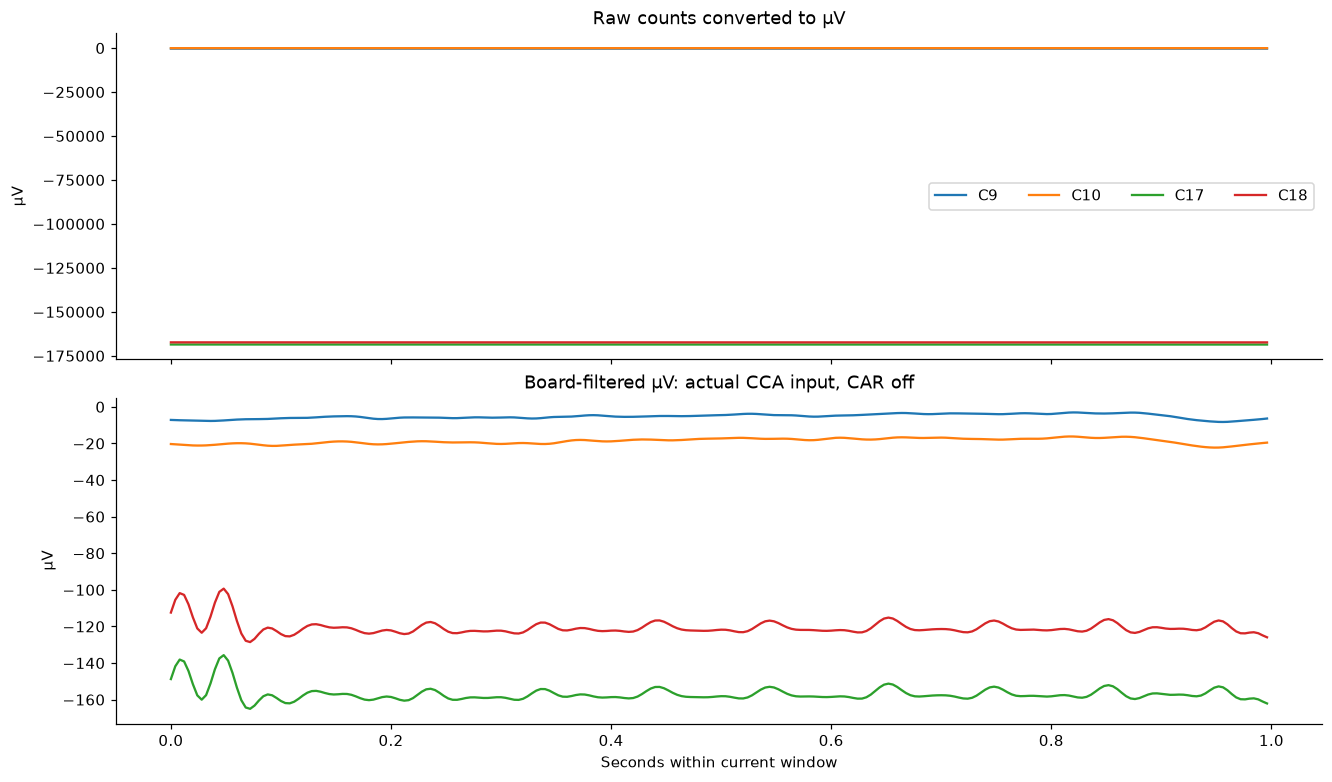

In [2]:
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True,constrained_layout=True)
for j in (0,1,8,9):
    axes[0].plot(t,raw_uv[:,j],label=CHANNEL_NAMES[j])
    axes[1].plot(t,eeg[:,j],label=CHANNEL_NAMES[j])
axes[0].set(title="Raw counts converted to µV",ylabel="µV")
axes[1].set(title="Board-filtered µV: actual CCA input, CAR off",xlabel="Seconds within current window",ylabel="µV")
axes[0].legend(ncol=4);plt.show()

## 2. Use the lines the board actually uses

Before comparing patterns, the board processes the measurements continuously. In plain terms:
- Keep extreme values within limits. This is called **clamping**.
- Limit the effect of an unusually sudden jump.
- Reduce a slowly changing offset. This part is called a **DC blocker**.
- Multiply recent measurements by 61 stored numbers and add them. This part is a **filter**. Its 61 numbers are called **taps**.
- Keep the output within limits again.

The filter's history continues from earlier measurements. We use the filtered values already saved by the board; we do not pretend to restart its filter at the beginning of the displayed second.

The first graph below shows the 61 stored multipliers. Some are negative, so those measurements subtract from the total. The second graph shows how much the linear filtering passes or reduces waves at each repetition rate: **1 means the same amplitude, 0.5 means half the amplitude, 0 means none**. This graph does not include the sudden-jump and extreme-value rules.

The active firmware selects physical channels **C9 through C24**, 16 channels in total. It does not subtract the across-channel average: the setting named CAR is off. Next we will subtract each channel's own **time average**, a different operation.

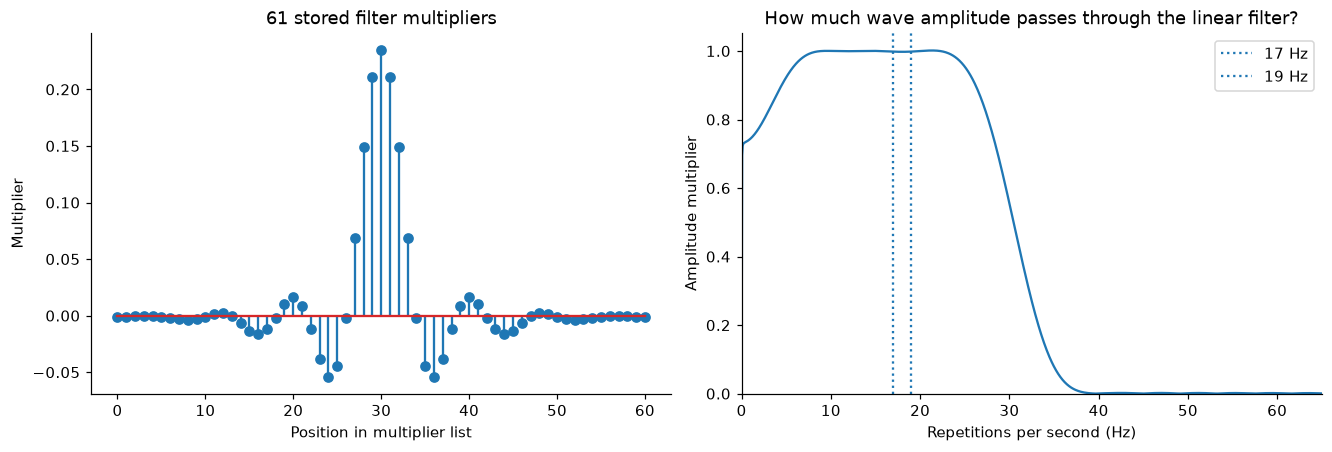

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axes[0].stem(np.arange(len(FIR_TAPS)),FIR_TAPS)
axes[0].set(title="61 stored filter multipliers",xlabel="Position in multiplier list",ylabel="Multiplier")
frequencies_front,hfir=signal.freqz(FIR_TAPS[::-1],fs=FS,worN=2048)
_,hdc=signal.freqz([1,-1],[1,-DC_R],fs=FS,worN=2048)
axes[1].plot(frequencies_front,abs(hfir*hdc))
for target in TARGETS:axes[1].axvline(target,ls=":",label=f"{target:g} Hz")
axes[1].set(title="How much wave amplitude passes through the linear filter?",
            xlim=(0,65),xlabel="Repetitions per second (Hz)",ylabel="Amplitude multiplier",ylim=(0,None))
axes[1].legend();plt.show()


## 3. A table of measurements, with each channel's average removed

A **matrix** is just a rectangular table of numbers. Here each row is a moment; each column is a channel. There are 250 rows and 16 columns.

First find the average down each channel column, then subtract it from every entry in that column.

For example, a column **[2, 4, 6]** has average **(2 + 4 + 6) ÷ 3 = 4**. Subtracting 4 gives **[−2, 0, 2]**. We kept the changes while removing the overall level.

The board does this with all 250 values in each channel. Call the resulting table **X**. A positive value means above that channel's time average; a negative value means below it. This operation is called **centering**.

In each picture below, one colored square is one number. The left table contains measurements, the middle has one average per channel, and the right contains the centered measurements. Red means positive, blue means negative, and pale means near zero. The color scale is displayed beside each panel; the scales can differ.

Centering is repeated for every new window. We have not divided by a channel's size or otherwise made the channels equal in size.

Computers round numbers; the largest remaining column average is: 4.8034668e-05


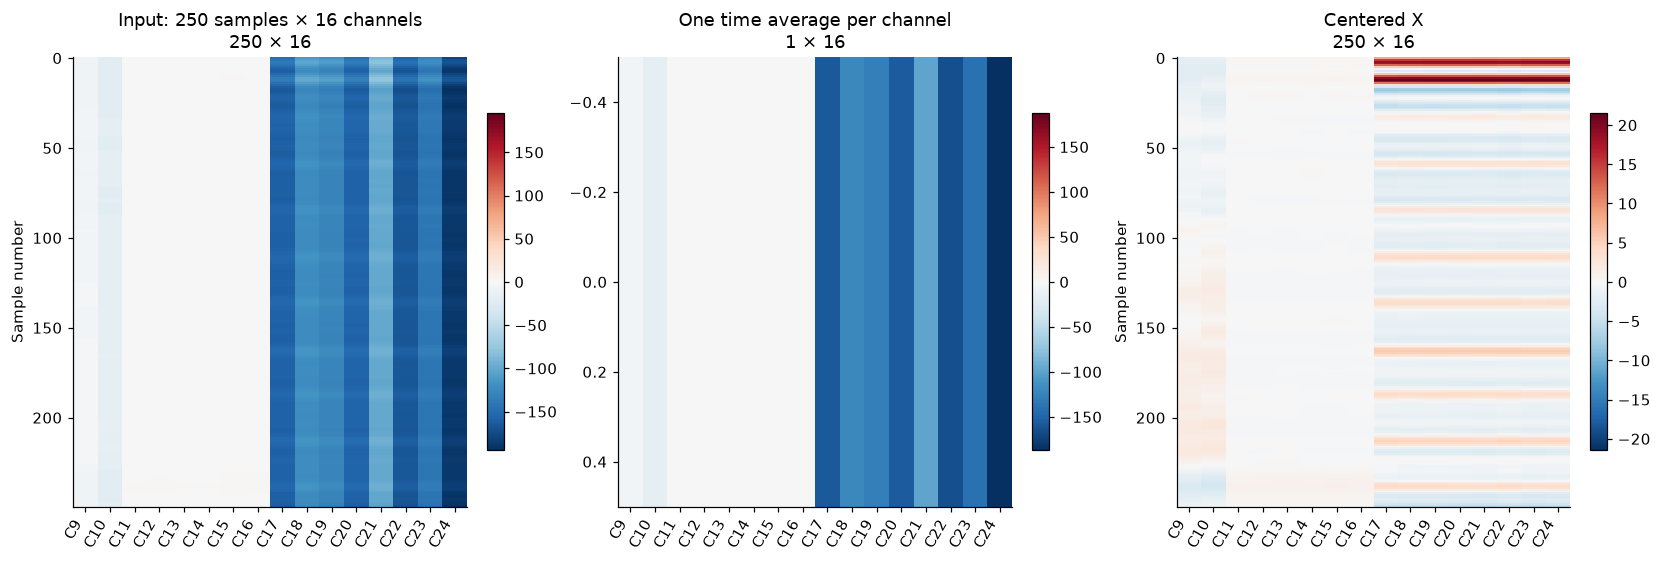

,C9,C10,C11,C12
sample,,,,
0,-7.15717,-20.3290,0.969895,1.023080
1,-7.25298,-20.4858,1.053060,1.120300
2,-7.32872,-20.6665,1.081240,1.151580
3,-7.38346,-20.8446,1.042310,1.102700
4,-7.42924,-20.9955,0.954916,0.995254
5,-7.48362,-21.1023,0.862128,0.879745


In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,5),constrained_layout=True)
heatmap(axes[0],eeg,"Input: 250 samples × 16 channels",columns=CHANNEL_NAMES)
heatmap(axes[1],q["x_mean"][None,:],"One time average per channel",columns=CHANNEL_NAMES)
heatmap(axes[2],q["X"],"Centered X",columns=CHANNEL_NAMES)
axes[0].set_ylabel("Sample number");axes[2].set_ylabel("Sample number");plt.show()
display(pd.DataFrame(eeg[:6,:4],columns=CHANNEL_NAMES[:4]).rename_axis("sample"))
print("Computers round numbers; the largest remaining column average is:",abs(q["X"].mean(0)).max())

## 4. Reference lines show the pattern we want to compare

A reference is a line of numbers we construct, rather than measure from an electrode.

A **sine wave** repeats smoothly. A **cosine wave** has the same shape but begins a quarter of a cycle ahead. With both lines available, we can later mix them to make peaks happen earlier or later. The lesson will show that mixing explicitly.

For 17 Hz, each reference repeats 17 times per second. For 19 Hz, it repeats 19 times per second. The firmware has a separate two-column reference table for each target: one sine column and one cosine column. Call such a table **Y**.

The left panels show the lines over time. The right panels store the exact same values as colored tables, with 250 rows and two columns. The firmware stores these reference numbers ahead of time and starts their row count at zero for each new window.

This build uses just these two waves per target. It does not add waves at twice or three times the target frequency.

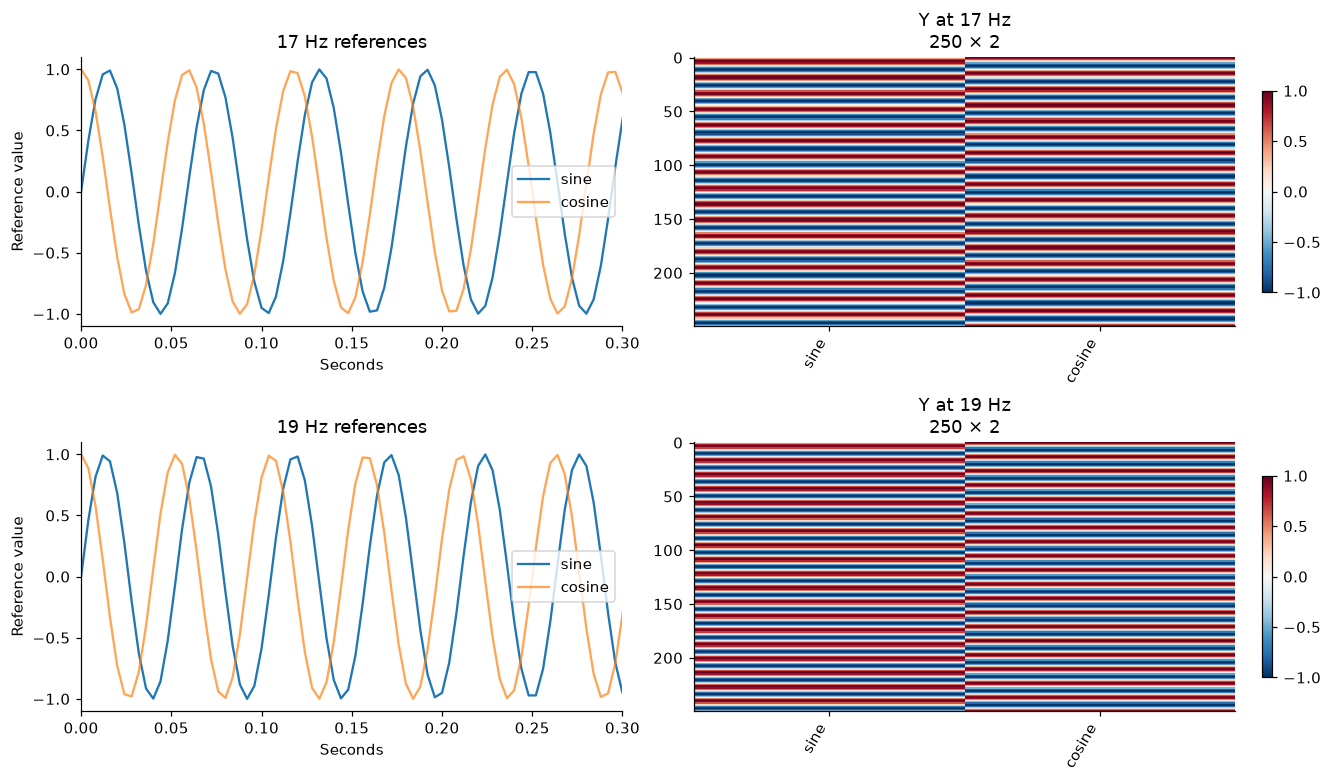

In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
for j,ff in enumerate(fits):
    axes[j,0].plot(t,ff["Y"][:,0],label="sine")
    axes[j,0].plot(t,ff["Y"][:,1],label="cosine",alpha=.7)
    axes[j,0].set(title=f"{ff['frequency']:g} Hz references",xlim=(0,.3),xlabel="Seconds",ylabel="Reference value")
    axes[j,0].legend()
    heatmap(axes[j,1],ff["Y"],f"Y at {ff['frequency']:g} Hz",columns=["sine","cosine"])
plt.show()

## 5. Multiply corresponding entries and add them

Pick one EEG column and one reference column. At each recorded moment, multiply their two values.

Two positive values give a positive answer. Two negative values also give a positive answer. Opposite signs give a negative answer.

Now add the answers over the window. This gives **one comparison total** for this EEG column and this reference column.

The first table below shows the first six actual moments. The last column adds the products as we go. The first plot shows one product per moment; the second shows the accumulated total.

We will soon store many such totals in tables. Before doing that, the next section uses small, easy numbers to explain what a total can and cannot tell us.

Full comparison total for C9 and sine = -4.7421494


,X: C9,Y: 17 Hz sine,multiply,running total
0,-1.922028,0.000000,-0.000000,-0.000000
1,-2.017838,0.414376,-0.836143,-0.836143
2,-2.093578,0.754251,-1.579084,-2.415227
3,-2.148318,0.958522,-2.059209,-4.474436
4,-2.194098,0.990461,-2.173169,-6.647605
5,-2.248478,0.844328,-1.898453,-8.546058


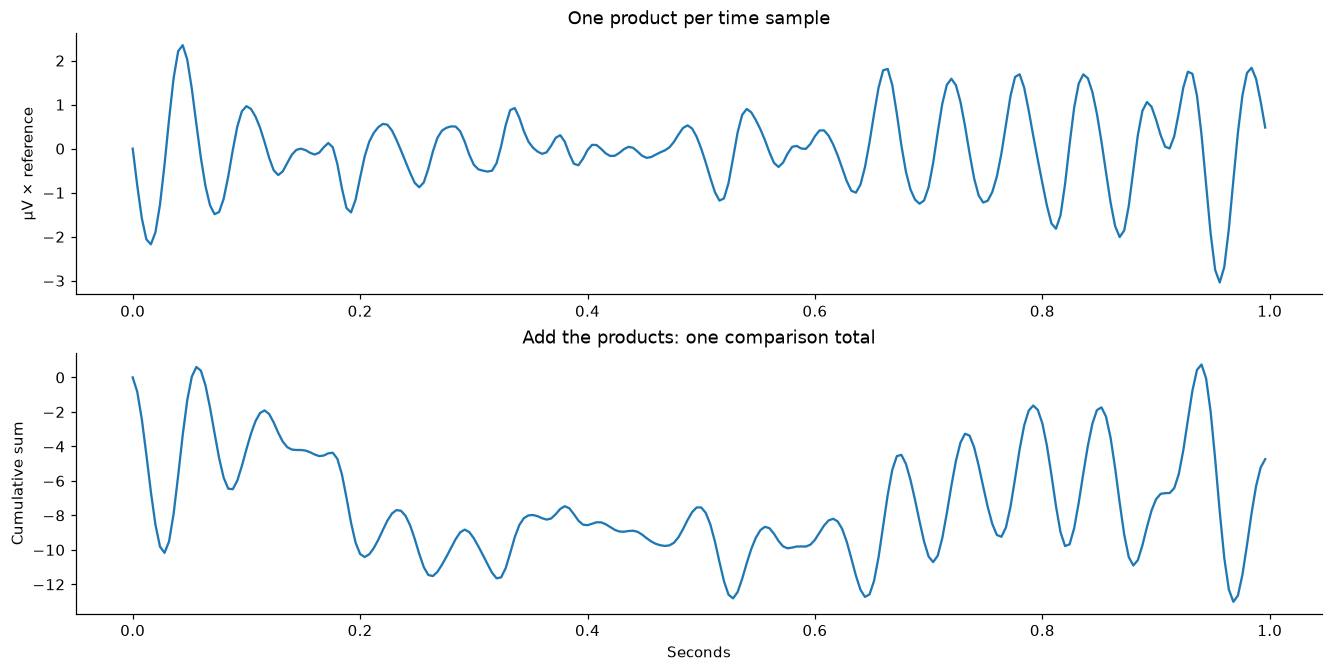

In [6]:
x=fit["X"][:,0]; y=fit["Y"][:,0]; product=x*y
display(pd.DataFrame({"X: C9":x[:6],"Y: 17 Hz sine":y[:6],
                      "multiply":product[:6],"running total":np.cumsum(product[:6])}))
fig,axes=plt.subplots(2,1,figsize=(12,6),constrained_layout=True)
axes[0].plot(t,product);axes[0].set(title="One product per time sample",ylabel="µV × reference")
axes[1].plot(t,np.cumsum(product));axes[1].set(title="Add the products: one comparison total",
                                             xlabel="Seconds",ylabel="Cumulative sum")
plt.show()
print("Full comparison total for C9 and sine =",fit["Cxy"][0,0])

## 6. Stay with four numbers before returning to EEG

You already know this operation: take entries at the same moment, multiply them, then add the answers. Let us keep doing only that.

Use this reference list: **[1, 2, −1, −2]**. If another line has exactly the same four values, the multiplications are:

| Moment | Other line | Reference | Multiply |
|---|---:|---:|---:|
| 1 | 1 | 1 | 1 |
| 2 | 2 | 2 | 4 |
| 3 | −1 | −1 | 1 |
| 4 | −2 | −2 | 4 |

Adding the last column gives **1 + 4 + 1 + 4 = 10**.

“Product” means the answer to a multiplication. “Product sum” means the answer after adding those products. Here the product sum is 10. It is simply a number obtained from these four rows.

Now make the other line ten times taller: **[10, 20, −10, −20]**. Its ups and downs occur at exactly the same moments as before. But the four products become 10, 40, 10, 40, adding to **100**.

So 100 does **not** mean the timing matches ten times better than when the result was 10. The line was just made ten times taller. This is the problem we need to solve before using these totals to judge a match.

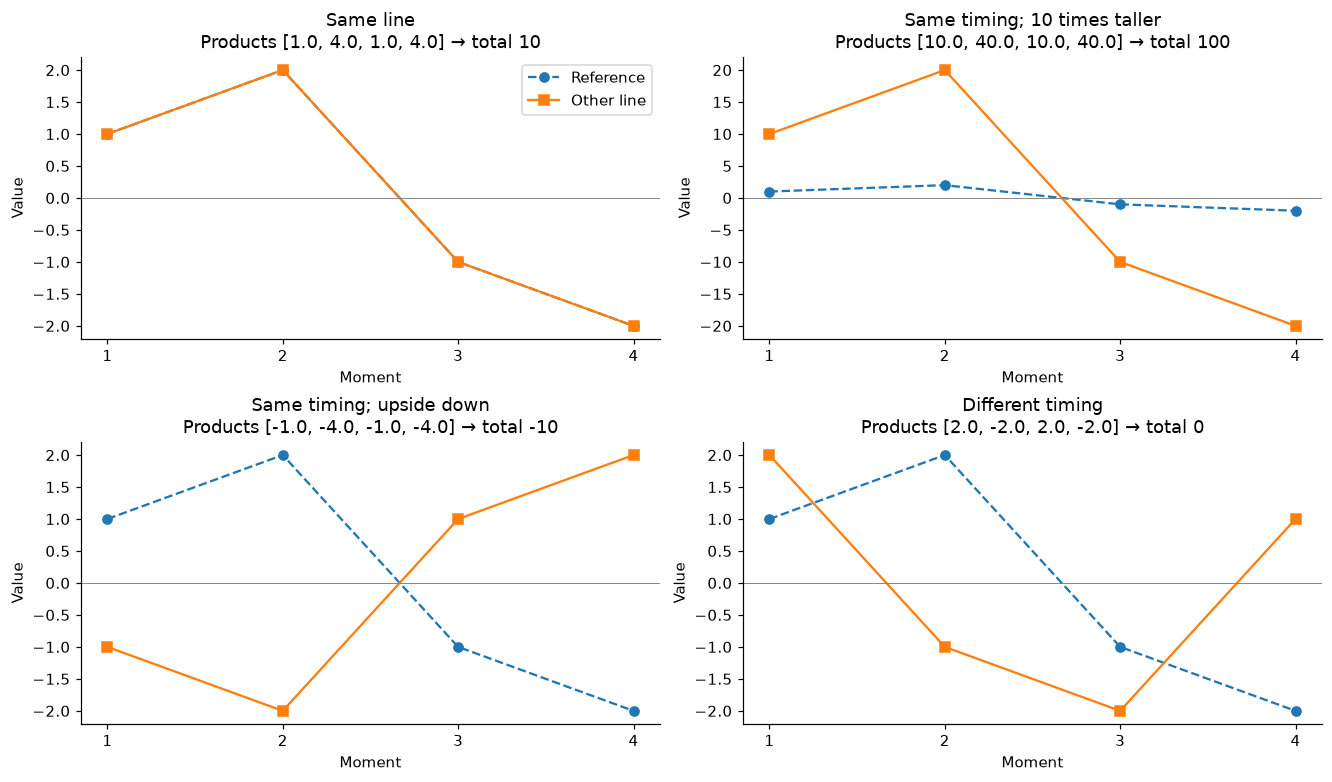

In [7]:
reference_demo=np.array([1.,2.,-1.,-2.])
comparison_demo={
    "Same line":reference_demo.copy(),
    "Same timing; 10 times taller":10*reference_demo,
    "Same timing; upside down":-reference_demo,
    "Different timing":np.array([2.,-1.,-2.,1.])
}
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
for ax,(name,line) in zip(axes.flat,comparison_demo.items()):
    ax.plot(range(1,5),reference_demo,"o--",label="Reference")
    ax.plot(range(1,5),line,"s-",label="Other line")
    products=line*reference_demo
    ax.set(title=f"{name}\nProducts {products.tolist()} → total {products.sum():g}",
           xlabel="Moment",ylabel="Value",xticks=range(1,5))
    ax.axhline(0,color="gray",lw=.6)
axes.flat[0].legend();plt.show()

### Read all four cases

The same line gave **10**. Making it taller gave **100**, without improving its timing.

Turning it upside down gave **−10**: whenever the reference is positive, the other line is negative, and vice versa. That is still a consistent relationship. Later, CCA can choose a negative multiplier to turn a line back the other way.

The differently timed example gave **0**, because some positive and negative products cancelled. A zero total does not mean the other line contains no voltage. It means this particular multiply-and-add comparison found no net agreement.

We need a comparison that keeps the timing information while taking account of each line's size. To build it, we need two more ordinary arithmetic operations.

## 7. Measure a line's size without positive and negative values cancelling

Compare a line with **itself**. Each entry is multiplied by that same entry:
1 × 1 = 1; 2 × 2 = 4; (−1) × (−1) = 1; (−2) × (−2) = 4.

Multiplying a number by itself is called **squaring** it. Negative × negative is positive, so these entries cannot cancel when added. The total is **10**. For this lesson, call it the line's **squared size**. Signal processing also calls this kind of total an energy; it is not a measurement of electrical energy in joules.

For the ten-times-taller line, the squared values are 100, 400, 100, 400. Their total is **1,000**, which is 100 times the original total. Squaring a tenfold increase gives a hundredfold increase.

We want a size measure that grows tenfold, rather than a hundredfold. Take a **square root**: find the positive number that gives the squared size when multiplied by itself.

- The square root of 9 is 3, because 3 × 3 = 9.
- The square root of 10 is approximately 3.162, because 3.162 × 3.162 is approximately 10.
- The square root of 1,000 is approximately 31.623.

Now the taller line's size is ten times larger: 31.623 instead of 3.162.

,Squared entries,Add squared entries,Square root of that total
Line,,,
Same line,"[1.0, 4.0, 1.0, 4.0]",10.0,3.162278
Same timing; 10 times taller,"[100.0, 400.0, 100.0, 400.0]",1000.0,31.622777
Same timing; upside down,"[1.0, 4.0, 1.0, 4.0]",10.0,3.162278
Different timing,"[4.0, 1.0, 4.0, 1.0]",10.0,3.162278


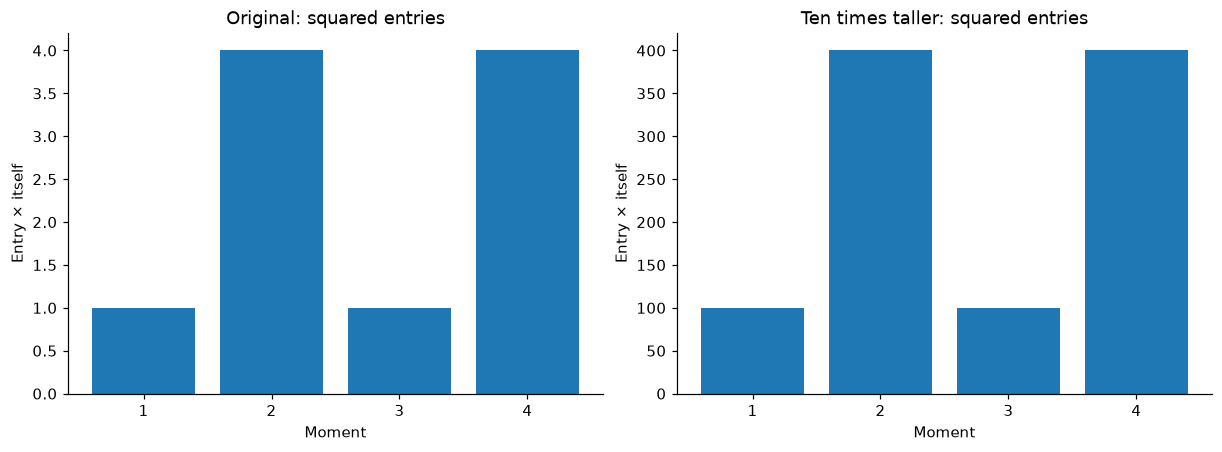

In [8]:
size_rows=[]
for name,line in comparison_demo.items():
    size_rows.append({"Line":name,"Squared entries":str((line*line).tolist()),
                      "Add squared entries":sum(line*line),"Square root of that total":np.sqrt(sum(line*line))})
display(pd.DataFrame(size_rows).set_index("Line"))
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,line,name in zip(axes,[reference_demo,10*reference_demo],["Original","Ten times taller"]):
    ax.bar(range(1,5),line*line)
    ax.set(title=f"{name}: squared entries",xlabel="Moment",ylabel="Entry × itself",xticks=range(1,5))
plt.show()

## 8. Make a fairer comparison

We now have three numbers:
1. Multiply corresponding entries of the two lines and add them.
2. Find the first line's size using the square root of its squared-entry total.
3. Find the second line's size the same way.

**Divide the number in step 1 by the two sizes multiplied together.**

For the identical lines: **10 ÷ (√10 × √10) = 10 ÷ 10 = 1**.

For the ten-times-taller line: **100 ÷ (√1,000 × √10) = 100 ÷ 100 = 1**.

Both now get the same result, as they should. The upside-down line gets **−1**. The differently timed example gets **0**.

When each line has had its own time average removed, this comparison is called **correlation**. An exact correlation lies between −1 and +1. +1 means identical up-and-down pattern after allowing a change of size; −1 means the opposite pattern; values near zero mean little net agreement by this comparison.

A result of 0.8 is not “80% attention,” “80% voltage,” or an 80% probability. It is a comparison number.

If either line is completely flat after removing its average, its size is zero. We cannot divide by zero. There is then no varying pattern to compare.

**This explains an ordinary correlation of two given lines.** Your firmware's approximate CCA score is calculated later by a different sequence of operations. We will not assume those two numbers are always identical.

,Multiply-and-add total,First size,Reference size,Divide by sizes multiplied together
Line,,,,
Same line,10.0,3.162278,3.162278,1.0
Same timing; 10 times taller,100.0,31.622777,3.162278,1.0
Same timing; upside down,-10.0,3.162278,3.162278,-1.0
Different timing,0.0,3.162278,3.162278,0.0


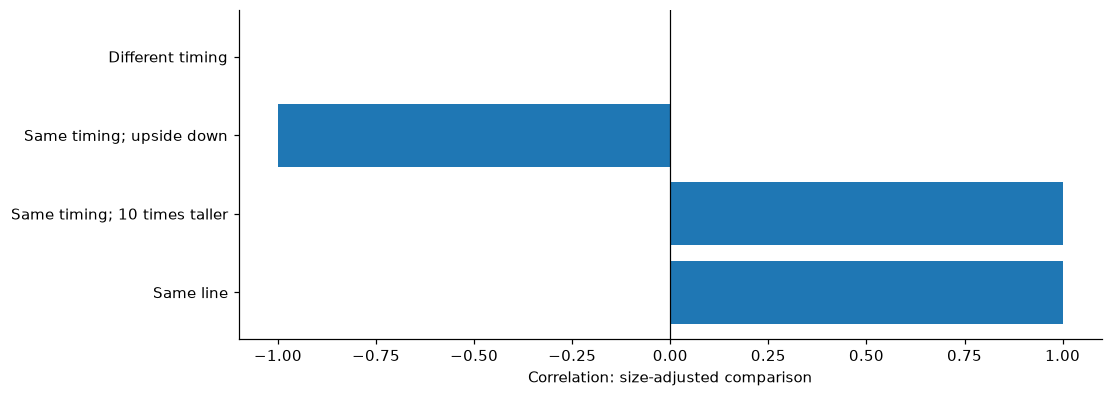

In [9]:
fair_rows=[]
for name,line in comparison_demo.items():
    total=sum(line*reference_demo)
    size1=np.sqrt(sum(line*line));size2=np.sqrt(sum(reference_demo*reference_demo))
    fair_rows.append({"Line":name,"Multiply-and-add total":total,
                      "First size":size1,"Reference size":size2,
                      "Divide by sizes multiplied together":total/(size1*size2)})
display(pd.DataFrame(fair_rows).set_index("Line").round(6))
fig,ax=plt.subplots(figsize=(10,3.5),constrained_layout=True)
ax.barh(list(comparison_demo),[r["Divide by sizes multiplied together"] for r in fair_rows])
ax.axvline(0,color="black",lw=.8);ax.set(xlim=(-1.1,1.1),xlabel="Correlation: size-adjusted comparison")
plt.show()

## 9. Why use more than one electrode?

Here is an invented example with only **four moments and two channels**. It is small so that every calculation can be checked. These are teaching numbers, not four rows from your recording.

Suppose one channel contains a wanted wave plus an unwanted wave. A second channel contains that same unwanted wave. We know how this example was constructed; for real EEG, we do not know the separate hidden waves.

| Moment | Wanted wave | Unwanted wave | Channel 1: wanted + 2 × unwanted | Channel 2: unwanted |
|---|---:|---:|---:|---:|
| 1 | 0 | 1 | 2 | 1 |
| 2 | 1 | −1 | −1 | −1 |
| 3 | 0 | 1 | 2 | 1 |
| 4 | −1 | −1 | −3 | −1 |

Looking at Channel 1 alone, the wanted wave is hard to see. Channel 2 alone does not contain it.

But at every moment, do **Channel 1 − 2 × Channel 2**:
- Moment 1: 2 − 2 × 1 = 0.
- Moment 2: −1 − 2 × (−1) = 1.
- Moment 3: 2 − 2 × 1 = 0.
- Moment 4: −3 − 2 × (−1) = −1.

We recovered **[0, 1, 0, −1]**, exactly the wanted wave. Combining channels can work better than choosing one channel.

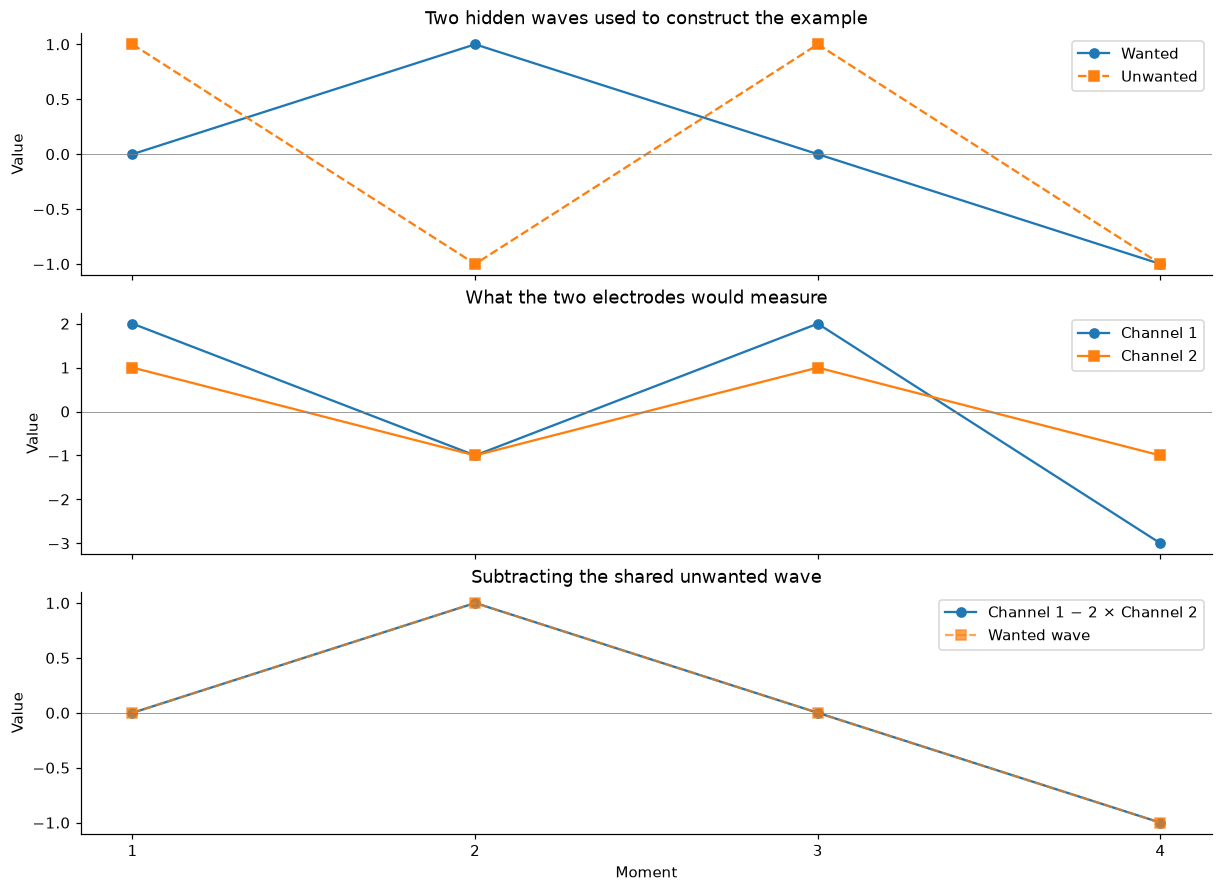

In [10]:
toy_sine=np.array([0.,1.,0.,-1.])
toy_cosine=np.array([1.,0.,-1.,0.])
toy_noise=np.array([1.,-1.,1.,-1.])
toy_x=np.column_stack((toy_sine+2*toy_noise,toy_noise))
toy_y=np.column_stack((toy_sine,toy_cosine))
toy_mix=toy_x[:,0]-2*toy_x[:,1]
fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True,constrained_layout=True)
axes[0].plot(range(1,5),toy_sine,"o-",label="Wanted")
axes[0].plot(range(1,5),toy_noise,"s--",label="Unwanted")
axes[0].set_title("Two hidden waves used to construct the example")
axes[1].plot(range(1,5),toy_x[:,0],"o-",label="Channel 1")
axes[1].plot(range(1,5),toy_x[:,1],"s-",label="Channel 2")
axes[1].set_title("What the two electrodes would measure")
axes[2].plot(range(1,5),toy_mix,"o-",label="Channel 1 − 2 × Channel 2")
axes[2].plot(range(1,5),toy_sine,"s--",label="Wanted wave",alpha=.7)
axes[2].set_title("Subtracting the shared unwanted wave")
for ax in axes:ax.legend();ax.set(ylabel="Value",xticks=range(1,5));ax.axhline(0,color="gray",lw=.5)
axes[2].set_xlabel("Moment");plt.show()

## 10. “Weights” are just the multipliers in that recipe

The recipe **1 × Channel 1 + (−2) × Channel 2** has two weights: **[1, −2]**.

A weight of 1 keeps that channel as it is. A weight of −2 flips its sign and doubles its size. A weight of 0 leaves that channel out. A weight of 0.5 uses half of it.

The list of weights is called a **vector**. Here that word only means an ordered list of numbers: first multiplier for the first channel, second multiplier for the second channel.

At each moment, multiply each channel value by its weight and add the answers. Doing that for all moments produces one new line. This is a **mixture** of the channel lines. Later we will also call it a **projection**.

In our example we can guess the useful recipe [1, −2], because we constructed the waves. In your 16-channel EEG, the useful recipe is unknown and changes with the window. CCA is a way to search for the recipe, using the reference waves to say what pattern we want.

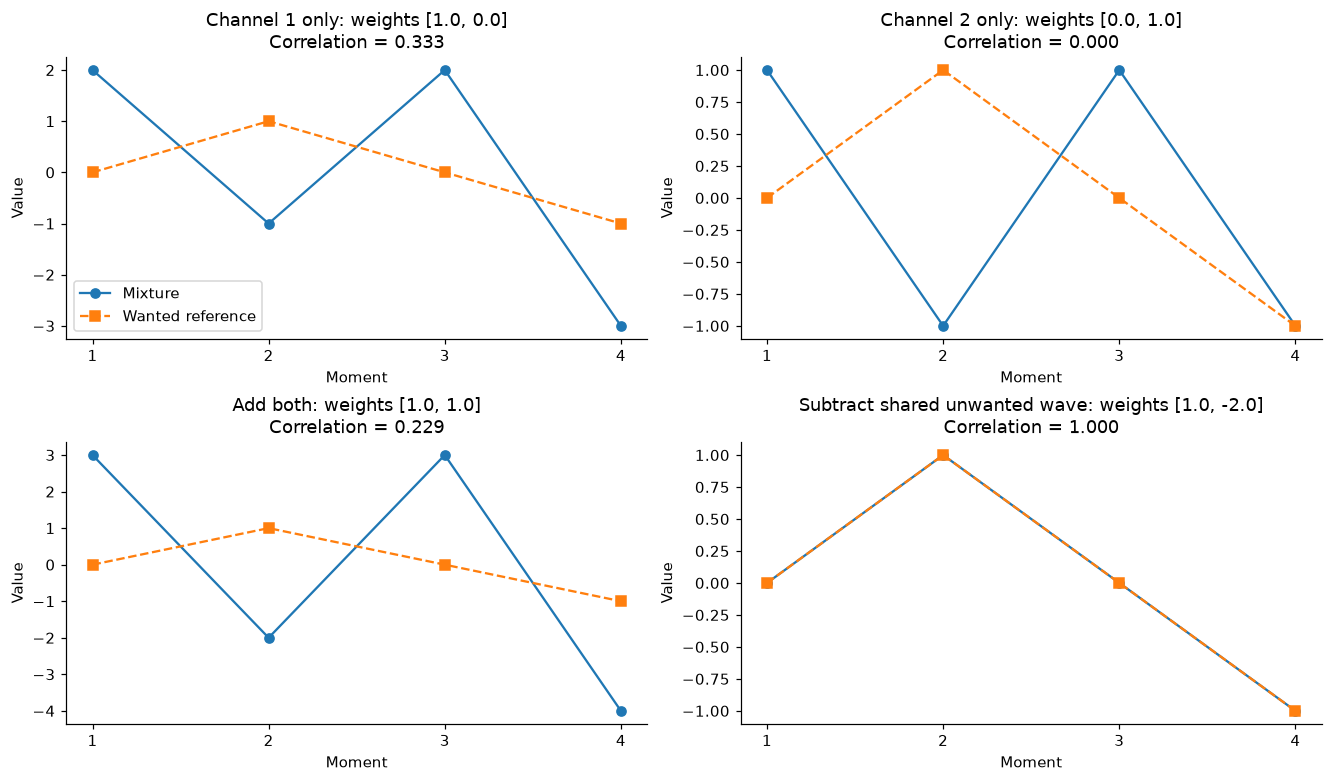

,Recipe,First weight,Second weight,Values of mixed line,Correlation
0,Channel 1 only,1.0,0.0,"[2.0, -1.0, 2.0, -3.0]",0.333333
1,Channel 2 only,0.0,1.0,"[1.0, -1.0, 1.0, -1.0]",0.000000
2,Add both,1.0,1.0,"[3.0, -2.0, 3.0, -4.0]",0.229416
3,Subtract shared unwanted wave,1.0,-2.0,"[0.0, 1.0, 0.0, -1.0]",1.000000


In [11]:
recipes={"Channel 1 only":[1,0],"Channel 2 only":[0,1],
         "Add both":[1,1],"Subtract shared unwanted wave":[1,-2]}
recipe_rows=[]
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
for ax,(name,weights) in zip(axes.flat,recipes.items()):
    weights=np.array(weights,float); mixed=toy_x@weights
    correlation=(mixed@toy_sine)/(np.linalg.norm(mixed)*np.linalg.norm(toy_sine))
    ax.plot(range(1,5),mixed,"o-",label="Mixture")
    ax.plot(range(1,5),toy_sine,"s--",label="Wanted reference")
    ax.set(title=f"{name}: weights {weights.tolist()}\nCorrelation = {correlation:.3f}",
           xlabel="Moment",ylabel="Value",xticks=range(1,5))
    recipe_rows.append({"Recipe":name,"First weight":weights[0],"Second weight":weights[1],
                       "Values of mixed line":mixed.tolist(),"Correlation":correlation})
axes.flat[0].legend();plt.show()
display(pd.DataFrame(recipe_rows))

## 11. Keep a recipe's size fixed while searching

The recipe [10, −20] produces a line ten times larger than [1, −2], but with exactly the same pattern. It should not win merely by using bigger multipliers.

The firmware keeps the weight list at a fixed size. We already know how to measure a list's size:
**square each number → add the squares → take the square root.**

For [1, −2]: the squared numbers are 1 and 4; their total is 5; the size is √5, approximately 2.236.

Divide **both** weights by 2.236. The new recipe is approximately **[0.447, −0.894]**. Their squared values now add to **1**.

Both recipes remove the unwanted wave. The new mixture is smaller, but has the same pattern. This operation is called **normalizing the weights**. It changes the overall size of the recipe, not the ratio between its multipliers.

This fixed-size list is often called a **direction**. You can read “direction” here as “a particular set of relative channel multipliers.” It is not a direction in the room or on the scalp.

Add squared final weights: 0.9999999999999999


,Weight before,Divide by,Weight after,Square of weight after
Channel 1,1.0,2.236068,0.447214,0.2
Channel 2,-2.0,2.236068,-0.894427,0.8


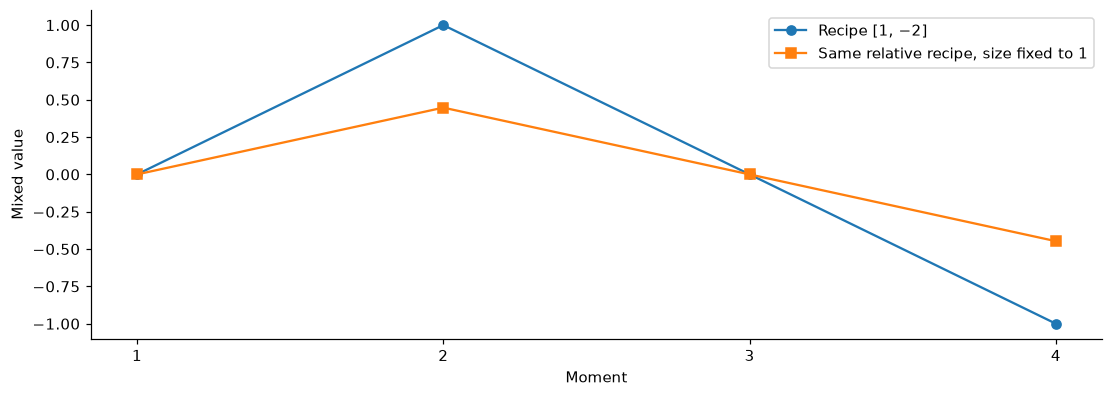

In [12]:
before=np.array([1.,-2.]); recipe_size=np.sqrt(sum(before*before));after=before/recipe_size
display(pd.DataFrame({"Weight before":before,"Divide by":recipe_size,"Weight after":after,
                      "Square of weight after":after*after},index=["Channel 1","Channel 2"]))
fig,ax=plt.subplots(figsize=(10,3.5),constrained_layout=True)
ax.plot(range(1,5),toy_x@before,"o-",label="Recipe [1, −2]")
ax.plot(range(1,5),toy_x@after,"s-",label="Same relative recipe, size fixed to 1")
ax.set(xlabel="Moment",ylabel="Mixed value",xticks=range(1,5));ax.legend();plt.show()
print("Add squared final weights:",sum(after*after))

## 12. Save all the comparisons in little tables

We could keep repeating the multiply-and-add operation for every question. Instead, calculate the answers once and place them in a table.

First compare the two EEG channels with themselves and with each other.

- Channel 1 with itself: 2² + (−1)² + 2² + (−3)² = **18**.
- Channel 2 with itself: 1² + (−1)² + 1² + (−1)² = **4**.
- Channel 1 with Channel 2: 2 × 1 + (−1) × (−1) + 2 × 1 + (−3) × (−1) = **8**.
- Channel 2 with Channel 1 gives the same **8**. Reversing the two numbers in each multiplication does not change the answer.

Put these four answers in a 2-by-2 table:

| Compare with → | Channel 1 | Channel 2 |
|---|---:|---:|
| Channel 1 | 18 | 8 |
| Channel 2 | 8 | 4 |

The firmware calls this table **Cxx**. The name is a label, not another calculation. It holds “EEG with EEG” comparisons.

The diagonal runs from the top-left to the bottom-right. Its entries, 18 and 4, compare a channel with itself. The other entries describe how the channels vary together. **These numbers have not yet been divided by sizes**, so they are not correlations.

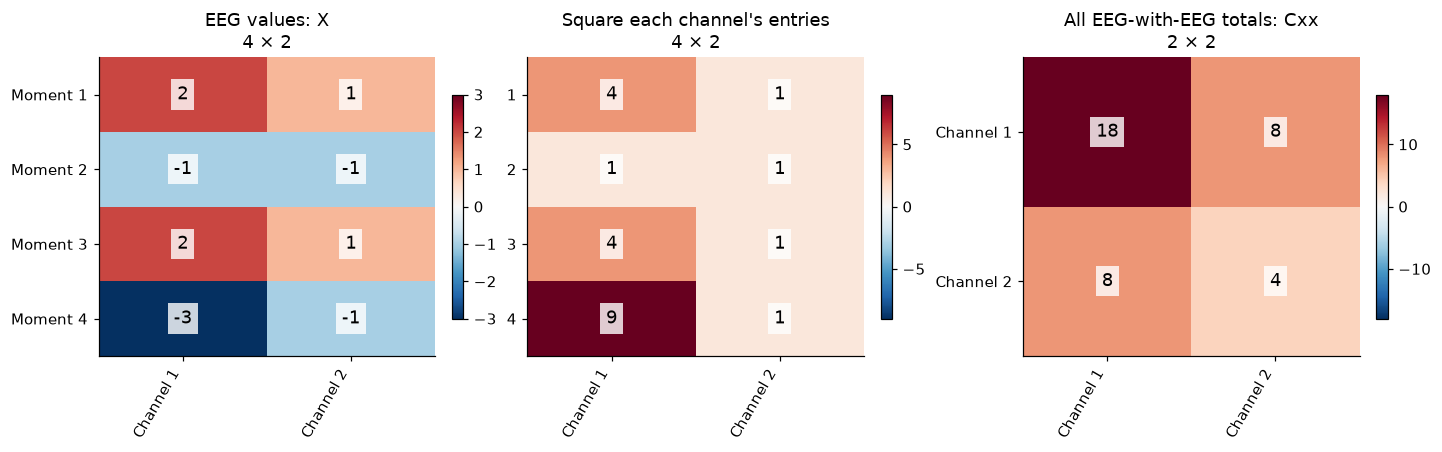

In [13]:
def show_small(ax,matrix,title,rows,columns):
    matrix=np.asarray(matrix,float)
    heatmap(ax,matrix,title,rows,columns)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j,i,f"{matrix[i,j]:.3g}",ha="center",va="center",
                    bbox={"facecolor":"white","alpha":.8,"edgecolor":"none"},fontsize=12)
toy_cxx=toy_x.T@toy_x
fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
show_small(axes[0],toy_x,"EEG values: X",["Moment 1","Moment 2","Moment 3","Moment 4"],["Channel 1","Channel 2"])
show_small(axes[1],toy_x*toy_x,"Square each channel's entries",["1","2","3","4"],["Channel 1","Channel 2"])
show_small(axes[2],toy_cxx,"All EEG-with-EEG totals: Cxx",["Channel 1","Channel 2"],["Channel 1","Channel 2"])
plt.show()

### Do the same thing for the reference columns

Our tiny reference table has two columns, the four values of a sine and a cosine:
**sine [0, 1, 0, −1]**, **cosine [1, 0, −1, 0]**.

Compare each EEG channel with each reference, multiplying corresponding moments and adding them:
- Channel 1 with sine: 2 × 0 + (−1) × 1 + 2 × 0 + (−3) × (−1) = **2**.
- Channel 1 with cosine: 2 × 1 + (−1) × 0 + 2 × (−1) + (−3) × 0 = **0**.
- Channel 2 with either reference gives **0**.

The answers form **Cxy**, meaning “EEG with references.”

Next compare the references with themselves and each other. Sine with itself gives **2**; cosine with itself gives **2**; sine with cosine gives **0**. These answers form **Cyy**, meaning “references with references.”

Cxx is needed because the EEG channels can share unwanted variation. Cyy accounts for the references' size and overlap. Cxy tells us which patterns they share with EEG. None of these tables alone is the final score.

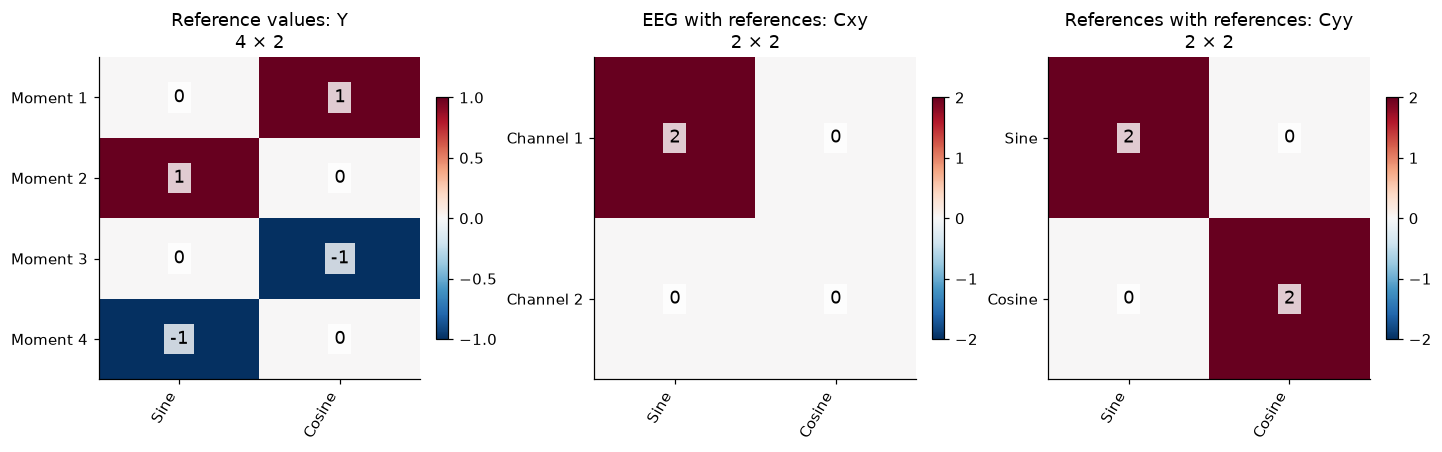

In [14]:
toy_cxy=toy_x.T@toy_y;toy_cyy=toy_y.T@toy_y
fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
show_small(axes[0],toy_y,"Reference values: Y",["Moment 1","Moment 2","Moment 3","Moment 4"],["Sine","Cosine"])
show_small(axes[1],toy_cxy,"EEG with references: Cxy",["Channel 1","Channel 2"],["Sine","Cosine"])
show_small(axes[2],toy_cyy,"References with references: Cyy",["Sine","Cosine"],["Sine","Cosine"])
plt.show()

## 13. What the notation means — no new arithmetic

A **matrix** is a table. A “16 × 2 matrix” has 16 rows and 2 columns.

A **transpose** turns rows into columns. It does not change any numbers. A little raised T means transpose: **Xᵀ** is X with its rows and columns exchanged.

Why do that? Original X has one channel down each column. Turning a column into a row lets the computer use the row-by-column multiply-and-add operation to compare it with another channel.

**XᵀX** means: take each channel from X, compare it with each channel from X, and save the answers in a table. That is exactly how we obtained Cxx.

Similarly:
- **XᵀY** gives Cxy.
- **YᵀY** gives Cyy.

In Python, the symbol **@** asks for this table multiplication. It is not entry-by-entry multiplication. **X @ weights** takes each moment's channel values, multiplies by the channel weights, and adds them.

You can always translate a table multiplication back into “one row, one column, multiply corresponding entries, add.” The new notation is only a shorter way to write familiar arithmetic.

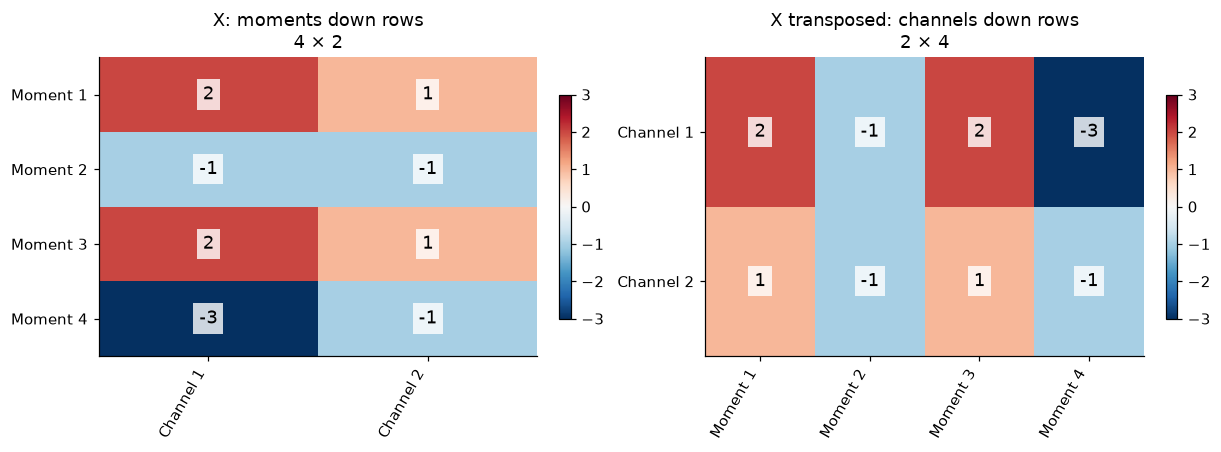

In [15]:
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
show_small(axes[0],toy_x,"X: moments down rows",["Moment 1","Moment 2","Moment 3","Moment 4"],["Channel 1","Channel 2"])
show_small(axes[1],toy_x.T,"X transposed: channels down rows",["Channel 1","Channel 2"],["Moment 1","Moment 2","Moment 3","Moment 4"])
plt.show()

## 14. Multiply a comparison table by a weight list

Use the table Cxx and the recipe [1, −2]. For its first row:
**18 × 1 + 8 × (−2) = 2**.

For its second row:
**8 × 1 + 4 × (−2) = 0**.

The result is the list **[2, 0]**.

These are not the four values of our mixed waveform. There are only two answers because this table has two rows. They say:
- Channel 1 compared with the mixed waveform gives 2.
- Channel 2 compared with the mixed waveform gives 0.

We can check that by first making the mixed waveform [0, 1, 0, −1], then directly comparing each EEG channel with it. We get the same answers.

Why? A mixture is built by adding weighted channels. Comparing an electrode with that mixture adds the same weighted comparisons. Cxx is a shortcut that already contains those comparisons.

This link matters: **given weights, Cxx tells us the channel-versus-mixture totals.** In a moment, we will need to go the other way: given desired comparison totals, find weights.

In [16]:
weights_demo=np.array([1.,-2.])
mixed_demo=toy_x@weights_demo
display(pd.DataFrame({"Cxx row":[str(r.tolist()) for r in toy_cxx],
                      "Multiply first entry by 1":toy_cxx[:,0],
                      "Multiply second entry by −2":-2*toy_cxx[:,1],
                      "Add":toy_cxx@weights_demo},index=["Channel 1 comparison","Channel 2 comparison"]))
display(pd.DataFrame({"Using Cxx @ weights":toy_cxx@weights_demo,
                      "Compare original channels with mixed waveform":toy_x.T@mixed_demo},
                     index=["Channel 1","Channel 2"]))

,Cxx row,Multiply first entry by 1,Multiply second entry by −2,Add
Channel 1 comparison,"[18.0, 8.0]",18.0,-16.0,2.0
Channel 2 comparison,"[8.0, 4.0]",8.0,-8.0,0.0


,Using Cxx @ weights,Compare original channels with mixed waveform
Channel 1,2.0,2.0
Channel 2,0.0,0.0


## 15. “Inverse” means a way to undo a transformation

Start with one number, 3. Multiply it by 2: you get 6. To recover the original number, divide 6 by 2. Division by 2 undoes multiplication by 2.

A table can transform several numbers together. We just transformed the weight list **[1, −2]** into comparison totals **[2, 0]** by multiplying by Cxx.

We want a second table that undoes that first table's transformation. Such a table is called its **inverse**. The little −1 in **Cxx⁻¹** names the undo table. It does not mean “make every entry negative,” and it does not mean “divide 1 by each entry separately.”

For our example, the undo table is:

| | First total | Second total |
|---|---:|---:|
| Recover first weight | 0.5 | −1 |
| Recover second weight | −1 | 2.25 |

Apply it to [2, 0]:
- First answer: 0.5 × 2 + (−1) × 0 = **1**.
- Second answer: (−1) × 2 + 2.25 × 0 = **−2**.

We recovered our recipe. Nothing mysterious happened: it was another multiply-and-add operation. What remains to explain is where this undo table came from.

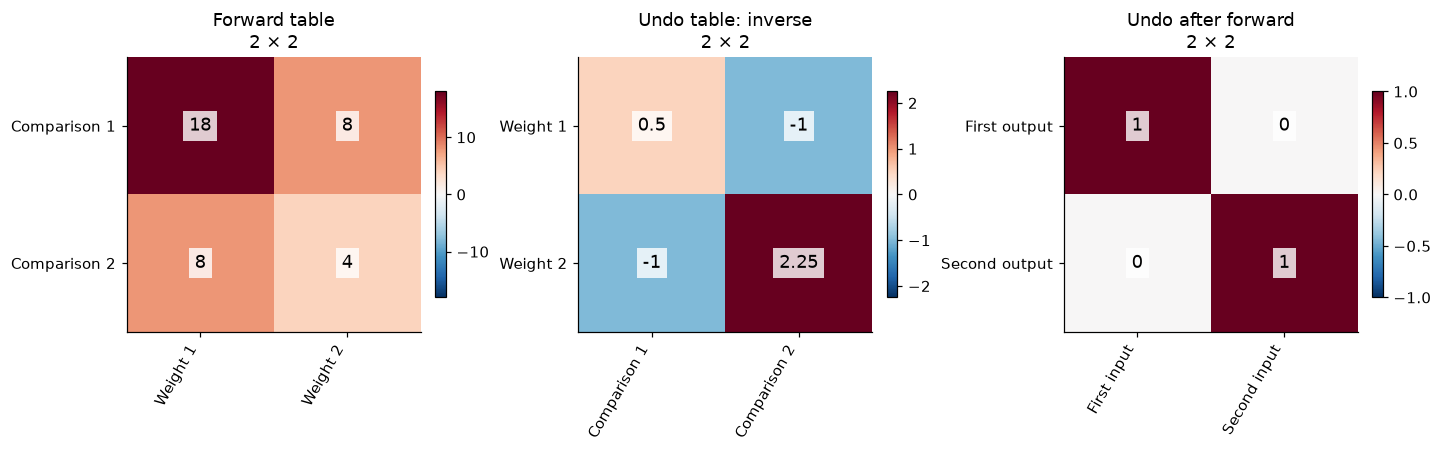

,Original weights,After forward table,Recovered with undo table
First number,1.0,2.0,1.0
Second number,-2.0,0.0,-2.0


In [17]:
toy_inv=np.linalg.inv(toy_cxx)
fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
show_small(axes[0],toy_cxx,"Forward table",["Comparison 1","Comparison 2"],["Weight 1","Weight 2"])
show_small(axes[1],toy_inv,"Undo table: inverse",["Weight 1","Weight 2"],["Comparison 1","Comparison 2"])
show_small(axes[2],toy_inv@toy_cxx,"Undo after forward",["First output","Second output"],["First input","Second input"])
plt.show()
display(pd.DataFrame({"Original weights":weights_demo,
                      "After forward table":toy_cxx@weights_demo,
                      "Recovered with undo table":toy_inv@(toy_cxx@weights_demo)},
                     index=["First number","Second number"]))

### The table with ones and zeros means “leave the numbers alone”

In the third panel above, the result is **[[1, 0], [0, 1]]**.

Multiplying this table by [1, −2] gives:
- 1 × 1 + 0 × (−2) = 1.
- 0 × 1 + 1 × (−2) = −2.

It leaves the input unchanged. This is called the **identity table** or identity matrix.

Checking “undo table × forward table = identity” is how we verify that an inverse really undoes the transformation. With rounded computer numbers, the answer can be very close to identity rather than perfectly equal.

## 16. How the computer finds the undo table

We will show the process once for two channels. You do not need to memorize it; the point is that “inverse” is calculated by ordinary subtraction and division.

Write our forward table on the left and the identity table on the right. Think of each row as one rule connecting input numbers to an output number.

Change both halves with the same row operations. Dividing a whole rule by a number preserves its meaning. Subtracting a multiple of another whole rule removes a repeated part.

Here are the operations, shown as numbered panels below:

1. **Start** with the forward table and identity.
2. **Divide the first row by 18.** Its first entry becomes 1.
3. **Subtract 8 times that first row from the second row.** The second row's first entry becomes 0. We have removed the first input from that row.
4. **Divide the second row by its second entry, 4/9 (approximately 0.444).** Its second entry becomes 1.
5. **Subtract 4/9 times the second row from the first row.** The first row's second entry becomes 0.

The left half has now become identity: it leaves an input unchanged. The right half has become the undo table. It is the same [0.5, −1; −1, 2.25] table we checked above.

This process is called **Gauss–Jordan elimination**. EMG32 does it with 16 rows, also choosing a suitable row at each step to avoid dividing by an unnecessarily small number. That row choice is called **pivoting**. These names describe the operations; you do not need another mathematical idea to follow them.

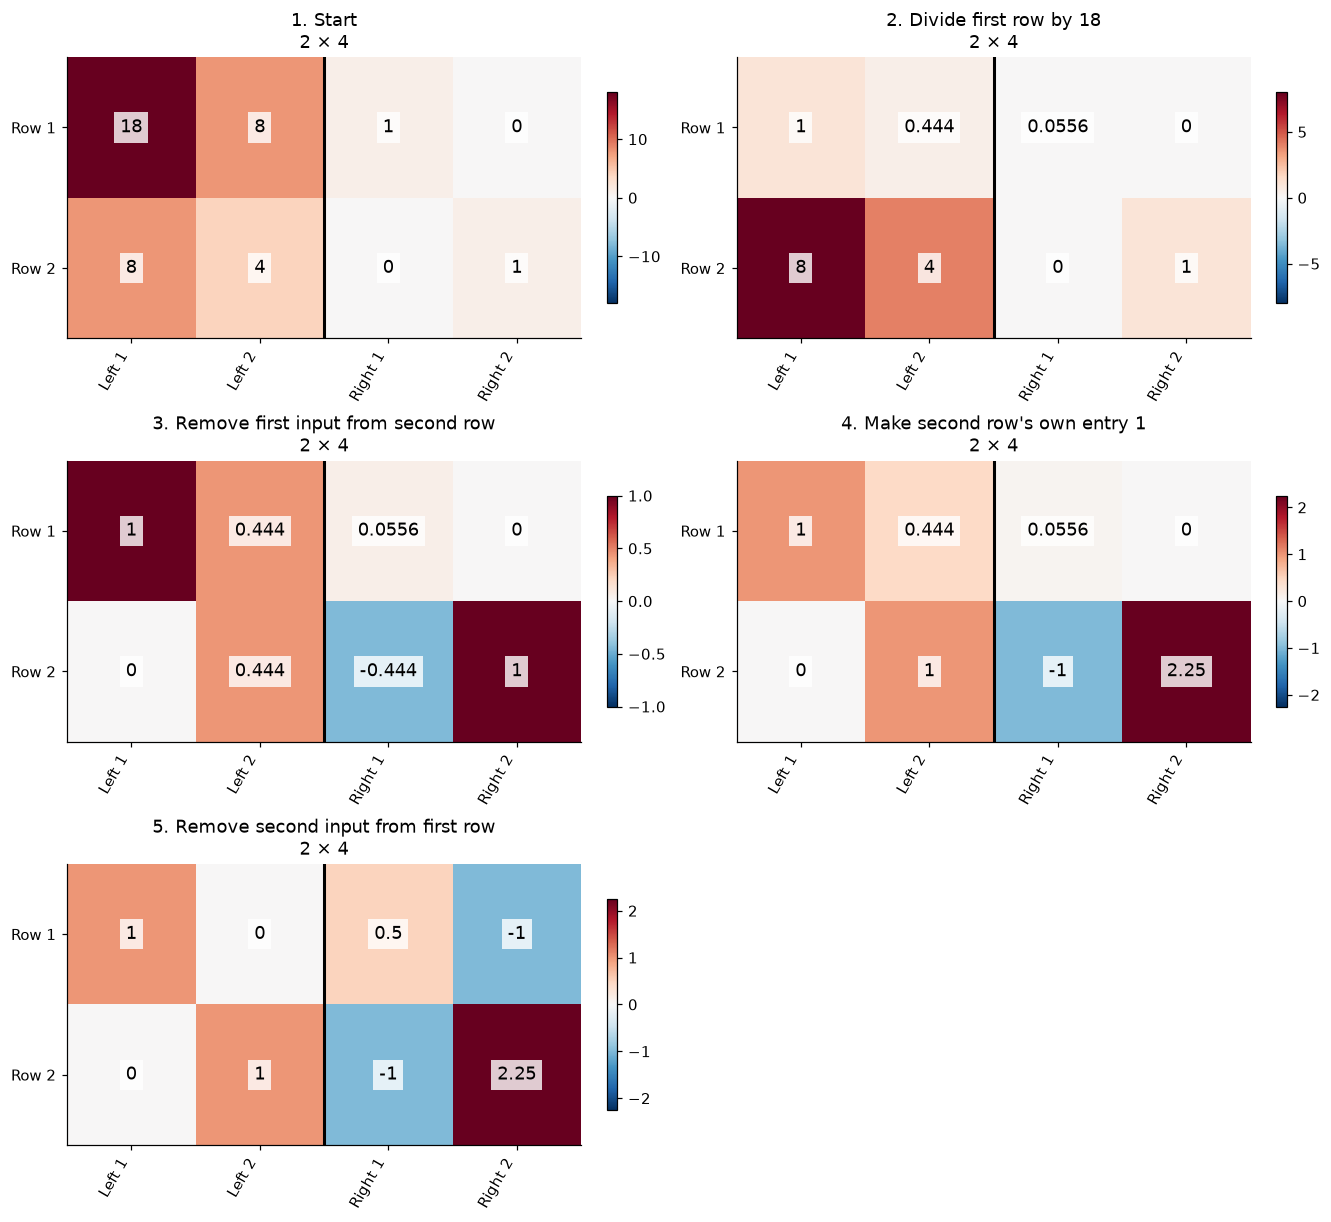

In [18]:
augmented=np.column_stack((toy_cxx,np.eye(2)))
undo_stages=[augmented.copy()]
augmented[0]/=18;undo_stages.append(augmented.copy())
augmented[1]-=8*augmented[0];undo_stages.append(augmented.copy())
augmented[1]/=augmented[1,1];undo_stages.append(augmented.copy())
augmented[0]-=augmented[0,1]*augmented[1];undo_stages.append(augmented.copy())
fig,axes=plt.subplots(3,2,figsize=(12,11),constrained_layout=True)
titles=["1. Start","2. Divide first row by 18","3. Remove first input from second row",
        "4. Make second row's own entry 1","5. Remove second input from first row"]
for ax,stage,title in zip(axes.flat,undo_stages,titles):
    show_small(ax,stage,title,["Row 1","Row 2"],["Left 1","Left 2","Right 1","Right 2"])
    ax.axvline(1.5,color="black",lw=2)
axes.flat[-1].axis("off");plt.show()
assert np.allclose(undo_stages[-1][:,:2],np.eye(2))
assert np.allclose(undo_stages[-1][:,2:],toy_inv)

## 17. Sometimes there is no unique way to undo a table

Suppose two channels are exact copies. The recipe [1, 0] produces the same line as [0, 1]. So does [0.5, 0.5]. Looking only at the mixed line, we cannot tell which recipe produced it.

That means the comparison table has lost information about the separate weights. A unique undo table does not exist. If the channels are almost copies, a unique undo may exist but be unreliable: a tiny change in a number can produce a large change in the recovered weights.

Your board makes the calculation more stable by adding a small positive number to each **diagonal** entry of Cxx. It leaves the off-diagonal entries unchanged.

Why the diagonal? Remember that a diagonal entry measures a channel with itself. Adding to those entries adds a small extra cost to using channel weights, without adding new shared-channel comparisons. A recipe with enormous opposing weights is discouraged. The fit becomes slightly less perfect in exchange for a more stable calculation.

This addition is called **regularization**. The added number is called **epsilon**. In the tiny duplicate-channel example below we use 0.1 so that the change is visible. That is a teaching choice, not your board's epsilon.

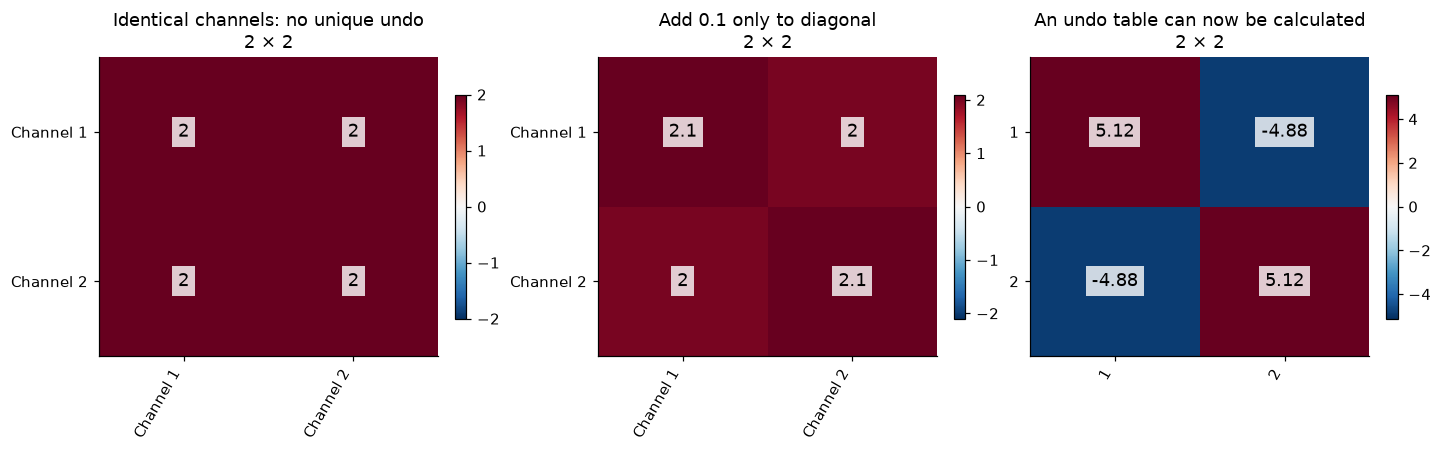

In [19]:
duplicate_cxx=np.array([[2.,2.],[2.,2.]])
duplicate_fixed=duplicate_cxx+.1*np.eye(2)
fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
show_small(axes[0],duplicate_cxx,"Identical channels: no unique undo",["Channel 1","Channel 2"],["Channel 1","Channel 2"])
show_small(axes[1],duplicate_fixed,"Add 0.1 only to diagonal",["Channel 1","Channel 2"],["Channel 1","Channel 2"])
show_small(axes[2],np.linalg.inv(duplicate_fixed),"An undo table can now be calculated",["1","2"],["1","2"])
plt.show()

### See how the diagonal addition discourages enormous opposing weights

Use two identical channels containing the same reference line. All three recipes below produce that same line because their two weights add to 1:
**[1, 0]**, **[0.5, 0.5]**, and **[10, −9]**.

Without the addition, their mixed line has the same squared size, 2.

Adding 0.1 to each diagonal changes the squared-size quantity used in the comparison by:
**0.1 × (first weight squared + second weight squared)**.

The three extra amounts are:
- [1, 0]: 0.1 × (1 + 0) = **0.1**.
- [0.5, 0.5]: 0.1 × (0.25 + 0.25) = **0.05**.
- [10, −9]: 0.1 × (100 + 81) = **18.1**.

The last recipe now has a much greater size cost despite producing the same desired line. When accounting for size to judge a match, that unnecessary cost makes it less attractive.

This cost is part of the calculation. The board does not physically add noise or voltage to your EEG.

In [20]:
duplicate_recipes=np.array([[1.,0.],[.5,.5],[10.,-9.]])
regularization_examples=[]
for recipe in duplicate_recipes:
    raw_quantity=float(recipe@duplicate_cxx@recipe)
    added=.1*sum(recipe*recipe)
    regularization_examples.append({"Weights":str(recipe.tolist()),
                                    "Original squared-size quantity":raw_quantity,
                                    "Added weight-size cost":added,
                                    "Modified squared-size quantity":raw_quantity+added})
display(pd.DataFrame(regularization_examples))

,Weights,Original squared-size quantity,Added weight-size cost,Modified squared-size quantity
0,"[1.0, 0.0]",2.0,0.10,2.10
1,"[0.5, 0.5]",2.0,0.05,2.05
2,"[10.0, -9.0]",2.0,18.10,20.10


### How much does EMG32 add?

For each new window:
1. Add the 16 diagonal entries of Cxx.
2. Divide that sum by 16 to get their average.
3. Multiply the average by **0.00001**.
4. If the result is smaller than **0.000001**, use 0.000001 instead.
5. Add the chosen result to all 16 diagonal entries.

The short expression **max(average diagonal × 1e−5, 1e−6)** says those same steps. “max” means choose the larger number. “1e−5” is computer shorthand for 0.00001; “1e−6” means 0.000001.

Call the modified table **A**. Therefore A is “Cxx with the small diagonal additions.” The firmware calculates **A⁻¹**, its undo table.

The reference comparison table also has a tiny diagonal addition, 0.00000001. Call that modified reference table **B**. The references do not change across windows, so EMG32 stores **B⁻¹** in advance instead of recomputing it every update.

In the next small example we temporarily omit these tiny additions to keep the numbers readable. We return to the actual regularized EMG32 tables afterward.

,Step,Number
0,Average of the 16 diagonal entries,2064.359863
1,Multiply by 0.00001,0.020644
2,Minimum allowed addition,0.000001
3,Actual addition chosen by firmware model,0.020644


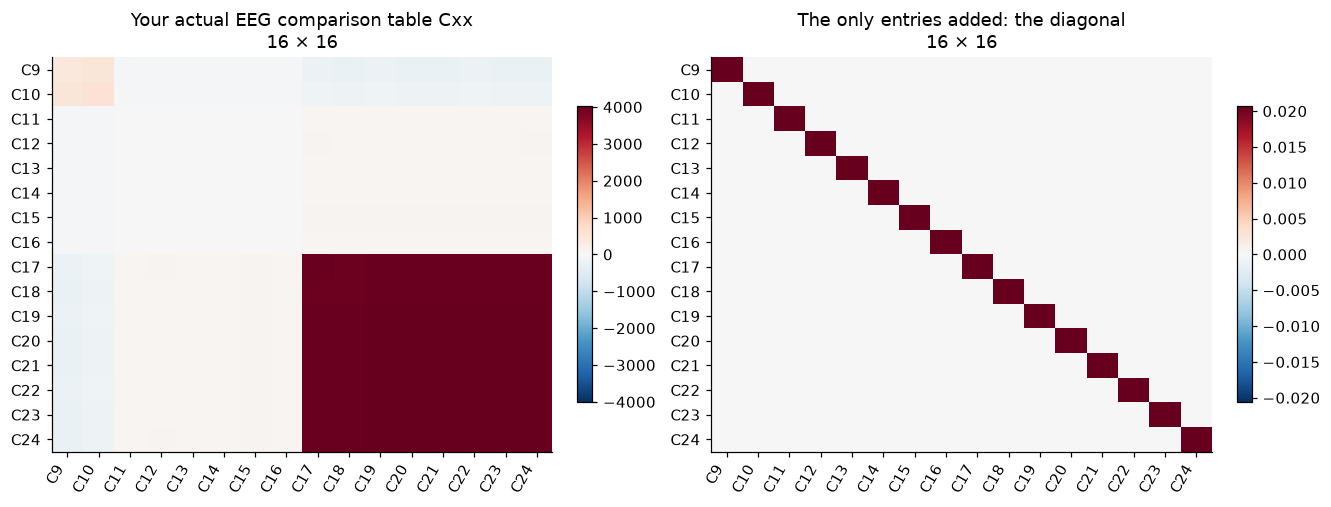

In [21]:
diagonal_average=float(np.trace(fit["Cxx"]))/16
display(pd.DataFrame({
    "Step":["Average of the 16 diagonal entries","Multiply by 0.00001",
            "Minimum allowed addition","Actual addition chosen by firmware model"],
    "Number":[diagonal_average,diagonal_average*.00001,.000001,fit["epsilon"]]}))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
heatmap(axes[0],fit["Cxx"],"Your actual EEG comparison table Cxx",CHANNEL_NAMES,CHANNEL_NAMES)
heatmap(axes[1],fit["epsilon"]*np.eye(16),"The only entries added: the diagonal",CHANNEL_NAMES,CHANNEL_NAMES)
plt.show()

## 18. The reference can also be a mixture

CCA does not require the EEG mixture to follow the sine column alone. It can mix sine and cosine too.

For example, a wanted line might be **sine + cosine**. Compared with sine alone, its correlation is about 0.707. Compared with cosine alone, it is also about 0.707. Compared with the mixture sine + cosine, its correlation is 1.

The two reference multipliers let the reference peaks move earlier or later within each cycle. That timing position is called **phase**. We do not need to know the EEG wave's phase before fitting it.

So the search has two recipes:
- EEG recipe: one multiplier for each electrode channel.
- Reference recipe: one multiplier for sine and one for cosine.

**CCA tries to find recipes whose resulting lines match well.** The firmware's repeated calculation below is an economical way to search for the strongest such match.

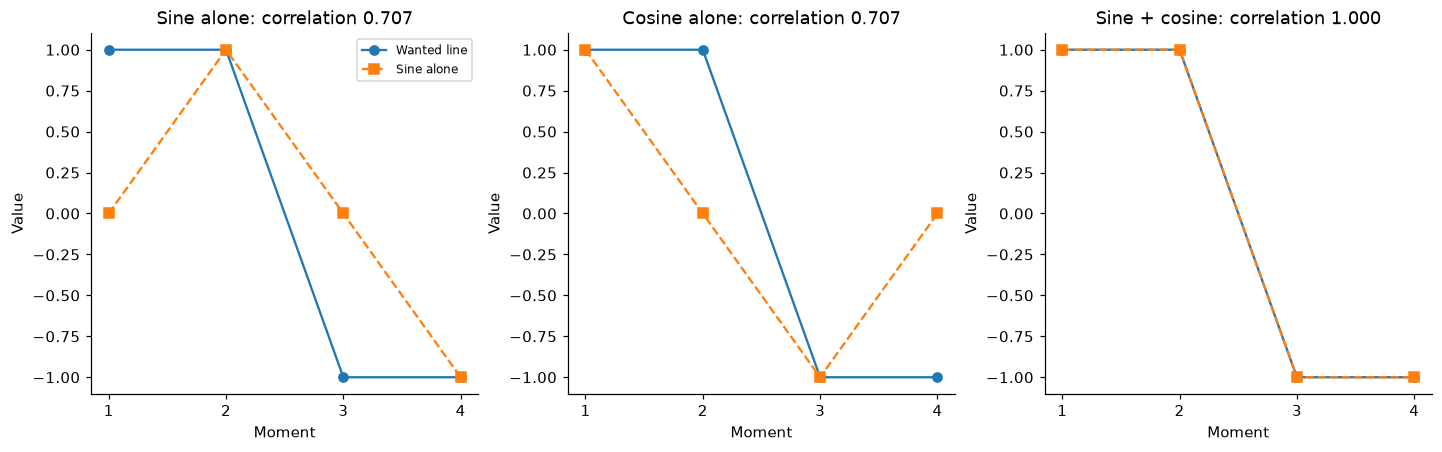

In [22]:
wanted_phase=toy_sine+toy_cosine
fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for ax,name,refline in zip(axes,["Sine alone","Cosine alone","Sine + cosine"],
                           [toy_sine,toy_cosine,wanted_phase]):
    match=(wanted_phase@refline)/(np.linalg.norm(wanted_phase)*np.linalg.norm(refline))
    ax.plot(range(1,5),wanted_phase,"o-",label="Wanted line")
    ax.plot(range(1,5),refline,"s--",label=name)
    ax.set(title=f"{name}: correlation {match:.3f}",xlabel="Moment",ylabel="Value",xticks=range(1,5))
axes[0].legend(fontsize=8);plt.show()

## 19. One search step, slowly: start with an ordinary guess

For two channels, start by giving them equal weights. Two weights of 1 have squared total 2 and size √2. Divide by √2 to get **[0.707, 0.707]**, approximately. This keeps the recipe's size at 1.

Make the EEG mixture using those weights. It contains some wanted sine and a lot of unwanted wave. We have not found the right recipe yet.

Now ask: **what mixture of the reference waves follows the reference-related part of this guessed EEG line?**

Compare the guessed EEG line with sine and cosine, using our familiar multiply-and-add operation. The totals are approximately **[1.414, 0]**.

Each reference has squared size 2. If a line contains 3 × sine, its comparison with sine is 3 × 2 = 6. To recover the multiplier 3, divide that comparison total by 2. Use the same reasoning here:

**Sine multiplier = 1.414 ÷ 2 = 0.707.**
**Cosine multiplier = 0 ÷ 2 = 0.**

The selected reference mixture is therefore 0.707 × sine. The unwanted wave has no net comparison with either reference and does not enter that mixture.

The inverse reference table automates those two divisions. If reference columns overlap, it also accounts for that overlap. This is what B⁻¹ is for.

,Reference,Compare with guessed EEG,Reference with itself,Reference multiplier
0,Sine,1.414214,2.0,0.707107
1,Cosine,0.000000,2.0,0.000000


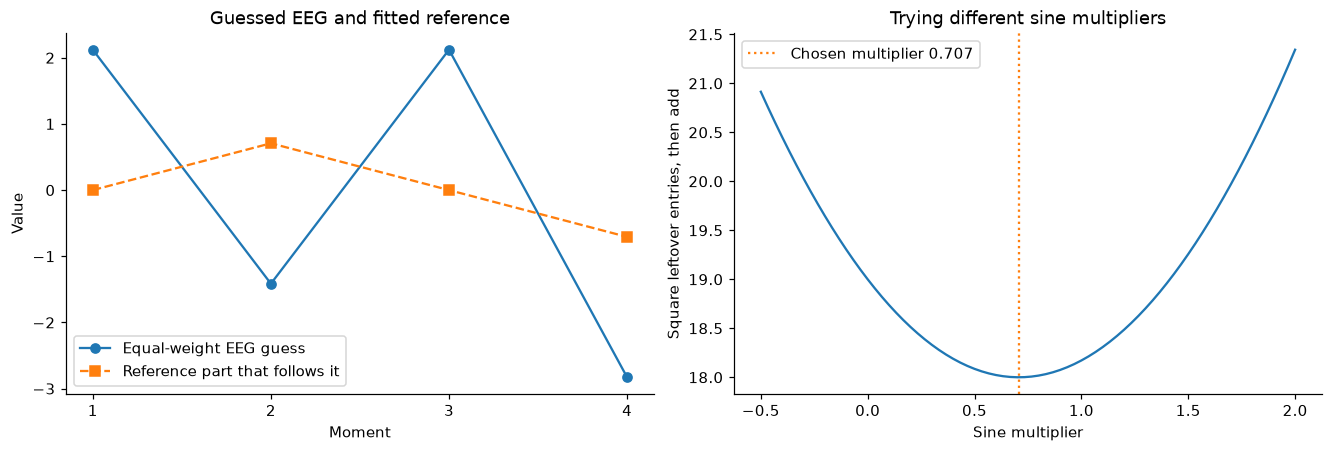

In [23]:
toy_guess=np.ones(2)/np.sqrt(2)
toy_guessed_line=toy_x@toy_guess
toy_reference_totals=toy_y.T@toy_guessed_line
toy_b=np.linalg.inv(toy_cyy)@toy_reference_totals
toy_reference_line=toy_y@toy_b
display(pd.DataFrame({"Reference":["Sine","Cosine"],
                      "Compare with guessed EEG":toy_reference_totals,
                      "Reference with itself":[2.,2.],
                      "Reference multiplier":toy_b}))
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axes[0].plot(range(1,5),toy_guessed_line,"o-",label="Equal-weight EEG guess")
axes[0].plot(range(1,5),toy_reference_line,"s--",label="Reference part that follows it")
axes[0].set(title="Guessed EEG and fitted reference",xlabel="Moment",ylabel="Value",xticks=range(1,5));axes[0].legend()
multipliers=np.linspace(-.5,2,151)
leftover_sizes=np.array([sum((toy_guessed_line-b*toy_sine)**2) for b in multipliers])
axes[1].plot(multipliers,leftover_sizes)
axes[1].axvline(toy_b[0],color="C1",ls=":",label=f"Chosen multiplier {toy_b[0]:.3f}")
axes[1].set(title="Trying different sine multipliers",
            xlabel="Sine multiplier",ylabel="Square leftover entries, then add");axes[1].legend()
plt.show()

### Why is that reference multiplier a good choice?

Subtract the selected reference line from the guessed EEG line. Call the result the **leftover**.

The right panel above tries many sine multipliers and measures the leftover's squared size. A small total means the reference line accounts for more of the guessed EEG line. The minimum occurs at the multiplier we calculated.

There is another way to understand it. If the leftover still has a consistent sine pattern, we can change the sine multiplier to absorb more of that pattern. The best choice leaves no net sine comparison in the leftover.

That condition says:
**“guessed EEG with sine” − “chosen multiplier × sine with itself” = 0.**

Rearrange the arithmetic: **chosen multiplier = first comparison ÷ second comparison**. This explains the division by reference size, rather than treating it as a formula to memorize.

For real EEG, the leftover includes everything these reference waves cannot explain. We are choosing a reference-related line, not proving that the leftover is meaningless or that the fitted part comes from a particular brain source.

## 20. Finish the step: find an EEG recipe for that reference line

We have selected a reference line: approximately 0.707 × sine. Now ask **which EEG weights reproduce that line?**

Compare each original EEG channel with that selected reference line. The totals are approximately **[1.414, 0]**.

Earlier we learned:
**Cxx × EEG weights = channel-versus-mixture comparison totals.**

So apply the undo table to the desired totals:
- First weight: 0.5 × 1.414 − 1 × 0 = **0.707**.
- Second weight: −1 × 1.414 + 2.25 × 0 = **−1.414**.

Those weights have the ratio **1 to −2** — exactly the recipe that removes the shared unwanted wave!

Finally divide both weights by their list's size, approximately 1.581. The new fixed-size recipe is **[0.447, −0.894]**.

We have completed one step:
**guess EEG weights → make EEG line → choose reference recipe → choose better EEG recipe → fix weight-list size.**

In this deliberately simple example, one step already finds the useful direction. With real EEG there are more channels and two possible matched directions, so the result may keep changing across steps.

,Channel,Compare with selected reference,Undo table gives these weights,Divide by weight-list size,Final fixed-size weights
0,1,1.414214,0.707107,1.581139,0.447214
1,2,0.000000,-1.414214,1.581139,-0.894427


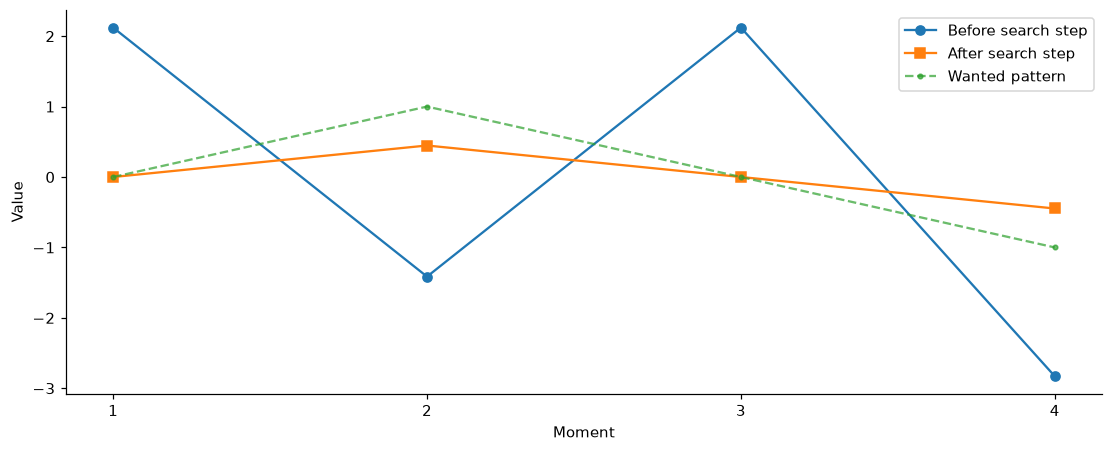

In [24]:
toy_channel_totals=toy_x.T@toy_reference_line
toy_new=toy_inv@toy_channel_totals
toy_new_size=np.sqrt(sum(toy_new*toy_new))
toy_new_normalized=toy_new/toy_new_size
display(pd.DataFrame({"Channel":["1","2"],"Compare with selected reference":toy_channel_totals,
                      "Undo table gives these weights":toy_new,
                      "Divide by weight-list size":toy_new_size,
                      "Final fixed-size weights":toy_new_normalized}))
fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
ax.plot(range(1,5),toy_x@toy_guess,"o-",label="Before search step")
ax.plot(range(1,5),toy_x@toy_new_normalized,"s-",label="After search step")
ax.plot(range(1,5),toy_sine,".--",label="Wanted pattern",alpha=.7)
ax.set(xlabel="Moment",ylabel="Value",xticks=range(1,5));ax.legend();plt.show()

## 21. A single table can perform that whole round trip

We have already collected the channel/reference comparisons in Cxy. Therefore the round trip can be written as four table operations, from right to left:

1. **Cxyᵀ × EEG weights**: get two EEG-mixture-versus-reference totals.
2. **B⁻¹ × those totals**: get the two reference multipliers.
3. **Cxy × reference multipliers**: get channel-versus-reference-mixture totals.
4. **A⁻¹ × those totals**: get updated EEG multipliers.

This is the same operation we just followed with four time samples. The tables save us from repeatedly going back through every sample during the weight search.

Because the four operations are fixed during one window, combine them into one table, named **M**:
**M = A⁻¹ Cxy B⁻¹ Cxyᵀ**.

Reading this formula from the right follows the four steps above. Multiplying M by a weight list performs the whole round trip in one go.

The firmware builds that table in this order:
- **T1 = Cxy B⁻¹**
- **T2 = T1 Cxyᵀ**
- **M = A⁻¹ T2**

T1 and T2 are simply names for intermediate tables. Multiplying table by table uses the same row-with-column multiply-and-add rule; it saves the output for every column.

Below, our tiny example gives **M = [[1, 0], [−2, 0]]**. Multiply that by [0.707, 0.707] and you get [0.707, −1.414], exactly the updated recipe we calculated above. The tiny example uses Cxx/Cyy without the small diagonal additions; the actual board uses A/B.

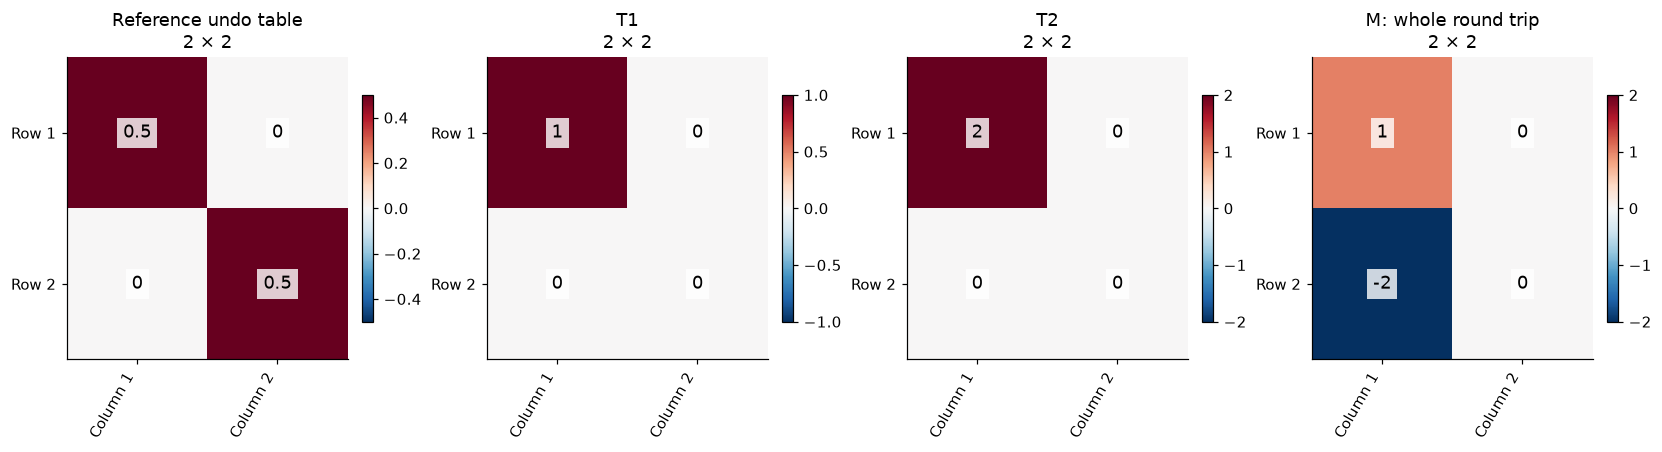

,Four stages followed above,One multiplication M @ old weights
New weight 1,0.707107,0.707107
New weight 2,-1.414214,-1.414214


In [25]:
toy_binv=np.linalg.inv(toy_cyy)
toy_t1=toy_cxy@toy_binv
toy_t2=toy_t1@toy_cxy.T
toy_m=toy_inv@toy_t2
fig,axes=plt.subplots(1,4,figsize=(15,4),constrained_layout=True)
for ax,m,name in zip(axes,[toy_binv,toy_t1,toy_t2,toy_m],
                     ["Reference undo table","T1","T2","M: whole round trip"]):
    show_small(ax,m,name,["Row 1","Row 2"],["Column 1","Column 2"])
plt.show()
display(pd.DataFrame({"Four stages followed above":toy_new,
                      "One multiplication M @ old weights":toy_m@toy_guess},index=["New weight 1","New weight 2"]))
assert np.allclose(toy_m@toy_guess,toy_new)

## 22. Now recognize the same tables in your real window

Only the table sizes have changed. There are **250 moments, 16 EEG channels, and two references per target**.

- X holds 250 rows of centered EEG.
- Y holds 250 rows of sine and cosine.
- Cxx and its modified version A have 16 rows and 16 columns.
- Cxy has 16 rows and 2 columns.
- B⁻¹ has 2 rows and 2 columns.
- M has 16 rows and 16 columns because it turns 16 old weights into 16 new weights.

Each square in a heat map is one number in the table. Red means positive, blue means negative, pale means nearer zero. **Each panel has its own color scale**: a bright red square in one panel need not have the same value as a bright red square in another.

The board calculates Cxx and A⁻¹ once for each window and reuses them for both targets. It builds a different Cxy and M for 17 Hz and 19 Hz, because the reference waves differ.

Large Cxx entries can reflect large voltages or shared variation. They are not automatically strong evidence of the target rhythm. Now you have seen why we need both the reference comparisons and the undo tables.

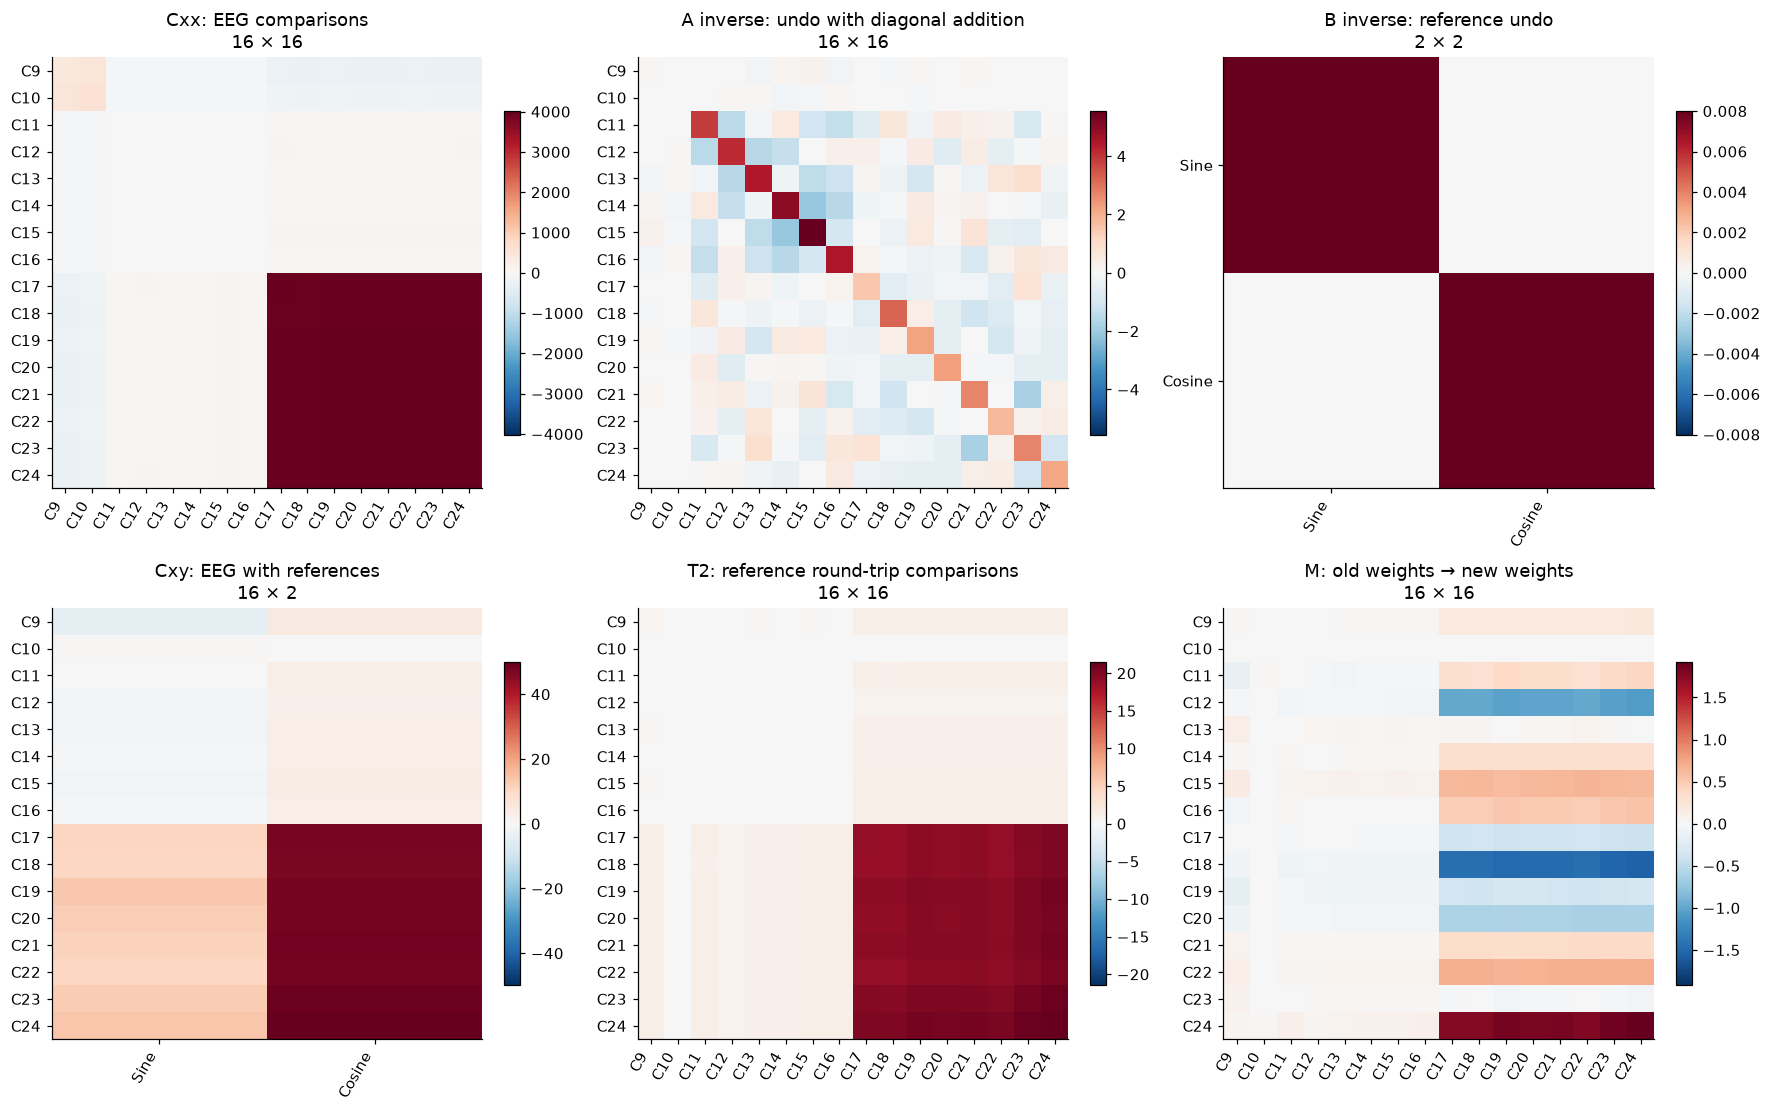

In [26]:
fig,axes=plt.subplots(2,3,figsize=(16,10),constrained_layout=True)
heatmap(axes[0,0],fit["Cxx"],"Cxx: EEG comparisons",CHANNEL_NAMES,CHANNEL_NAMES)
heatmap(axes[0,1],fit["A_inv"],"A inverse: undo with diagonal addition",CHANNEL_NAMES,CHANNEL_NAMES)
heatmap(axes[0,2],fit["B_inv"],"B inverse: reference undo",["Sine","Cosine"],["Sine","Cosine"])
heatmap(axes[1,0],fit["Cxy"],"Cxy: EEG with references",CHANNEL_NAMES,["Sine","Cosine"])
heatmap(axes[1,1],fit["T2"],"T2: reference round-trip comparisons",CHANNEL_NAMES,CHANNEL_NAMES)
heatmap(axes[1,2],fit["M"],"M: old weights → new weights",CHANNEL_NAMES,CHANNEL_NAMES)
plt.show()

## 23. Repeat the step eight times

For 16 channels, equal starting weights are **sixteen copies of 0.25**. Why 0.25?
Sixteen copies of 1 have squared total 16 and size √16 = 4. Divide each 1 by 4.

For each step:
1. Multiply the current weight list by M.
2. Square the 16 answers, add the squares, and take the square root.
3. Divide all 16 answers by that size.
4. Use the result as the next weight list.

The firmware does this **eight times**, separately for each target. This repeated operation is called **power iteration**. The name does not mean it is directly measuring EEG power.

The hope is that the recipe settles into a direction that the round trip repeatedly supports. Eight steps are a practical limit chosen by the code, not a guarantee of perfect convergence. If the multiplied list has size smaller than 0.000000000001, the firmware returns score zero instead of dividing by such a tiny number.

The plot below labels step 0 as the equal starting list. Steps 1 through 8 are the updated lists. These are the weights for one current EEG window, not eight different time windows.

The board rounds numbers as it calculates. Its number format, called float32, keeps roughly seven significant decimal digits. The notebook models that arithmetic. The historical CSV also rounds stored values, so a reconstructed result can differ from the board's recorded result. In the extra full-dimension calculation, the computer keeps more digits; that format is called double precision.

The table above shows the first step using readable arithmetic; firmware-order float32 rounding can differ slightly.


,Channel,Old weight,New answer before division,Divide by this size,New weight after division
0,C9,0.25,0.414782,6.178594,0.067132
1,C10,0.25,0.013931,6.178594,0.002255
2,C11,0.25,0.608466,6.178594,0.098480
3,C12,0.25,-2.095526,6.178594,-0.339159
4,C13,0.25,0.149552,6.178594,0.024205
5,C14,0.25,0.656007,6.178594,0.106174
6,C15,0.25,1.390582,6.178594,0.225064
7,C16,0.25,1.000417,6.178594,0.161917
8,C17,0.25,-0.800558,6.178594,-0.129570
9,C18,0.25,-3.103738,6.178594,-0.502337


,M first-row entry,Multiply by old weight,Product,Running sum
C9,0.029582,0.25,0.007396,0.007396
C10,-0.000981,0.25,-0.000245,0.007150
C11,0.013246,0.25,0.003312,0.010462
C12,0.013409,0.25,0.003352,0.013814
C13,0.017399,0.25,0.004350,0.018164
C14,0.016357,0.25,0.004089,0.022253
C15,0.018257,0.25,0.004564,0.026817
C16,0.016906,0.25,0.004227,0.031044
C17,0.190124,0.25,0.047531,0.078575
C18,0.190726,0.25,0.047681,0.126256


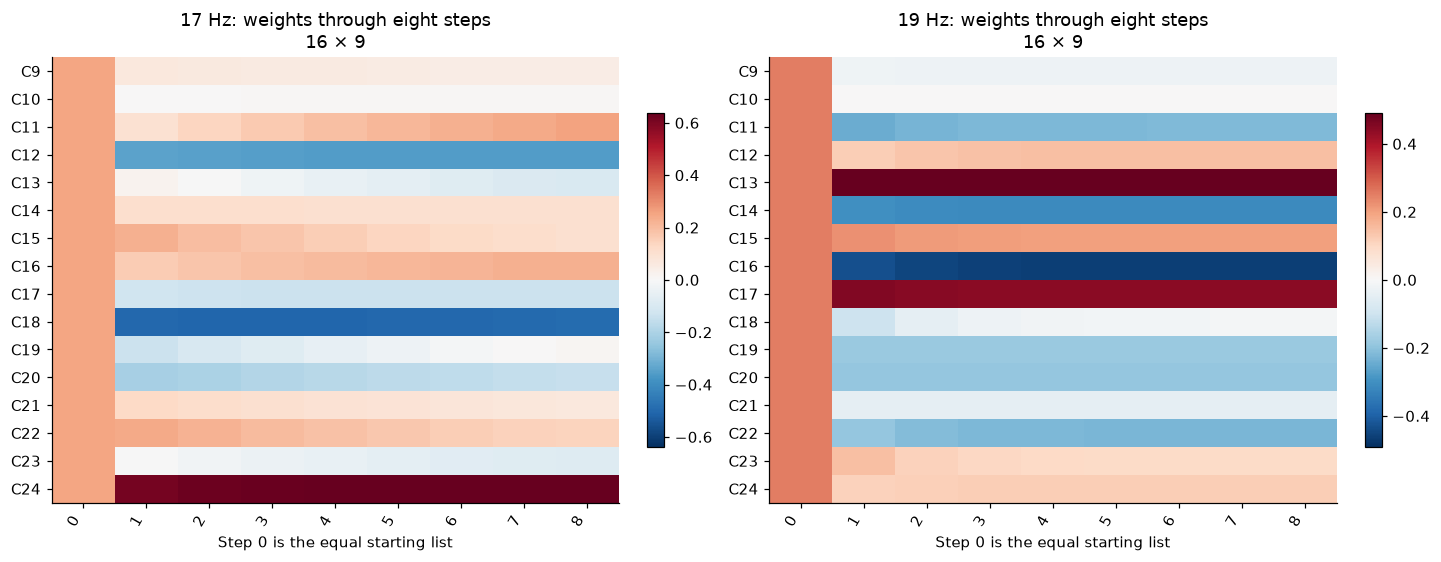

In [27]:
initial_weights=fit["vectors"][0]
first_unscaled=fit["M"]@initial_weights
first_size=np.sqrt(sum(first_unscaled*first_unscaled))
display(pd.DataFrame({"Channel":CHANNEL_NAMES,"Old weight":initial_weights,
                      "New answer before division":first_unscaled,
                      "Divide by this size":first_size,
                      "New weight after division":first_unscaled/first_size}))
display(pd.DataFrame({"M first-row entry":fit["M"][0],"Multiply by old weight":initial_weights,
                      "Product":fit["M"][0]*initial_weights,
                      "Running sum":np.cumsum(fit["M"][0]*initial_weights)},index=CHANNEL_NAMES))
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for ax,ff in zip(axes,fits):
    heatmap(ax,ff["vectors"].T,f"{ff['frequency']:g} Hz: weights through eight steps",
            CHANNEL_NAMES,[str(i) for i in range(9)])
    ax.set_xlabel("Step 0 is the equal starting list")
plt.show()
print("The table above shows the first step using readable arithmetic; firmware-order float32 rounding can differ slightly.")

## 24. What does it mean for the weights to settle?

Suppose multiplying a final weight list by M gives exactly **0.64 times that same list**. The numbers got smaller, but all their ratios stayed the same. Dividing by their size would return to the same relative recipe. The recipe has settled.

Mathematicians call such a recipe an **eigenvector**. They call the stretching factor, here 0.64, an **eigenvalue**. You can remember:
**eigenvector = a recipe whose relative weights survive the round trip**;
**eigenvalue = how much that round trip stretches it**.

You do not need these words to perform the calculation. They name the behavior we just described.

If a different recipe is supported more strongly by repeated round trips, repeated multiplication tends to favor it. That is the reason for using the iteration to seek the strongest matched direction. An equal starting guess can sometimes miss a direction, and eight steps may stop before settling.

For your actual window, the two lines below show the final weights and M multiplied by those weights. The second panel compares the result with “one estimated stretching factor times the original weights.” Any remaining mismatch means the eight-step result has not perfectly settled.

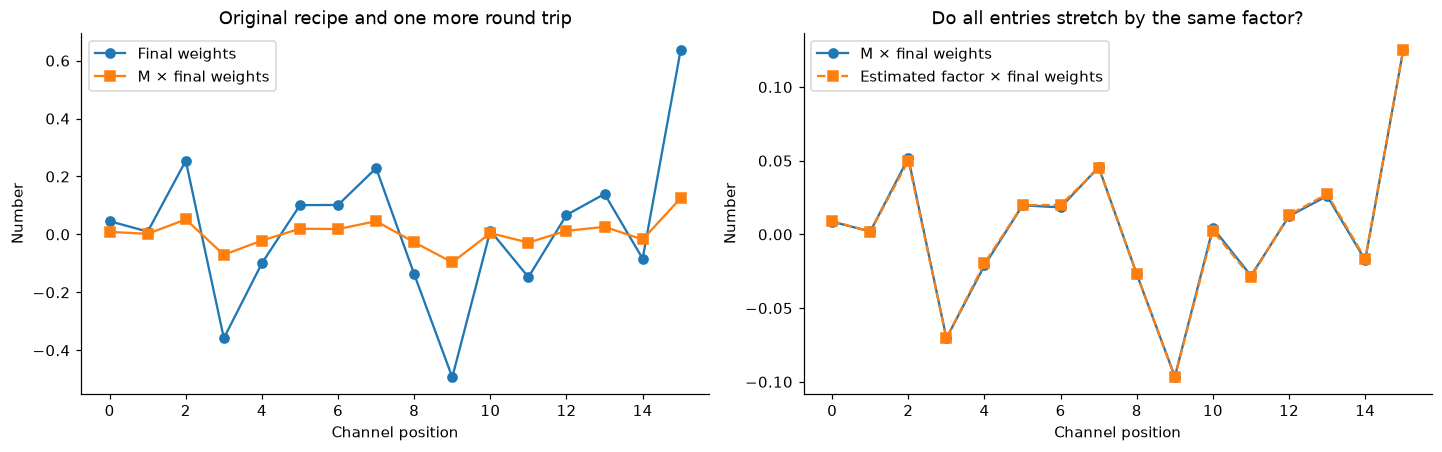

In [28]:
final_weights=fit["hw_weights"].astype(float)
roundtrip=fit["M"].astype(float)@final_weights
stretch_estimate=float(final_weights@roundtrip)
fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
axes[0].plot(range(16),final_weights,"o-",label="Final weights")
axes[0].plot(range(16),roundtrip,"s-",label="M × final weights")
axes[0].set(title="Original recipe and one more round trip",xlabel="Channel position",ylabel="Number");axes[0].legend()
axes[1].plot(range(16),roundtrip,"o-",label="M × final weights")
axes[1].plot(range(16),stretch_estimate*final_weights,"s--",label="Estimated factor × final weights")
axes[1].set(title="Do all entries stretch by the same factor?",xlabel="Channel position",ylabel="Number")
axes[1].legend();plt.show()

## 25. Turn the final list into the firmware score

The board now wants one number for this target:
1. Multiply M by the final weight list.
2. Multiply each answer by the corresponding entry of that same final weight list.
3. Add those 16 products.
4. If the total is negative, replace it with zero.
5. Take its square root.

The table below shows each of the 16 products. This is still arithmetic you know.

Why does step 3 estimate the stretching factor? If M returns 0.64 times the final weights, the products are 0.64 times each weight's square. The squared weights add to 1 because we fixed the list's size. Their total is therefore **0.64 × 1 = 0.64**.

Why take a square root? In the full CCA comparison, after accounting for the sizes and overlap of the lines, the EEG-to-reference-to-EEG round trip has a stretching factor equal to the **square** of the matching strength. A match of 0.8 in each direction corresponds to a round-trip factor 0.8 × 0.8 = 0.64. The square root returns 0.8.

The real board uses regularization, rounded arithmetic, and only eight steps. Its resulting score estimates that strongest match. It need not equal the ordinary correlation of a displayed pair of lines. M also need not be symmetric — meaning the entry across the diagonal can differ — so a not-yet-settled estimate is especially different from a full CCA solution.

The firmware does not clip the score at 1. The clipping to [−1,1] occurs later for **feedback**, after subtracting the two scores.

No ordinary real number multiplied by itself gives a negative answer. The negative-total guard prevents attempting a square root of a negative intermediate result. A zero returned by this guard is the firmware's handling rule, not negative EEG power.

In [29]:
score_products=final_weights*roundtrip
display(pd.DataFrame({"Final weight":final_weights,"M × final weights":roundtrip,
                      "Multiply corresponding entries":score_products,
                      "Running sum":np.cumsum(score_products)},index=CHANNEL_NAMES))
total=float(sum(score_products))
print("Add the products:",total)
print("Replace negative with zero, then square root:",np.sqrt(max(total,0)))
print("Firmware-order float32 model:",fit["hardware_score"])
print("Recorded board score for this update:",row.v3)
print("The model and the historical board value can differ; this is not a bit-exact replay.")

Add the products: 0.19649571760190016
Replace negative with zero, then square root: 0.4432783748412505
Firmware-order float32 model: 0.4432784914970398
Recorded board score for this update: 0.44522
The model and the historical board value can differ; this is not a bit-exact replay.


,Final weight,M × final weights,Multiply corresponding entries,Running sum
C9,0.045616,0.008656,0.000395,0.000395
C10,0.009748,0.002005,0.000020,0.000414
C11,0.254462,0.051823,0.013187,0.013601
C12,-0.358282,-0.070398,0.025222,0.038824
C13,-0.099436,-0.021055,0.002094,0.040917
C14,0.101135,0.019738,0.001996,0.042913
C15,0.101714,0.018335,0.001865,0.044778
C16,0.228896,0.045677,0.010455,0.055234
C17,-0.137458,-0.027016,0.003713,0.058947
C18,-0.493202,-0.096453,0.047571,0.106518


### Why the final square root appears: check a one-line example

Temporarily use just one EEG line and one reference line, with their averages already removed. Omit the tiny diagonal additions for this example.

EEG values: **[1, 2, −1, −2]**.
Reference values: **[1, 1, −1, −1]**.

Our familiar totals are:
- EEG with itself: 1 + 4 + 1 + 4 = **10**.
- Reference with itself: 1 + 1 + 1 + 1 = **4**.
- EEG with reference: 1 + 2 + 1 + 2 = **6**.

With a single number, the undo table for 10 is simply **1/10**; the undo table for 4 is **1/4**.

The complete round-trip table has one entry:
**(1/10) × 6 × (1/4) × 6 = 36/40 = 0.9.**

We used the EEG/reference comparison **twice**, once in each direction. That is why the 6 gets squared.

The ordinary size-adjusted comparison we learned earlier is:
**6 ÷ (√10 × √4) ≈ 0.948683.**

Square that result and you get **0.9**. Take the square root of 0.9 and you recover **0.948683**.

This is a numerical explanation of the square root, not an extra rule to memorize. For many channels, the stretching factor plays the role of this single round-trip number. The board estimates it using the final weight list as described above.

If the one-line comparison were negative, using it twice would still give a positive square. CCA can flip the reference mixture's sign to match an upside-down pattern. Its nonnegative strength does not report the sign of an ordinary two-line correlation.

In [30]:
one_eeg=np.array([1.,2.,-1.,-2.])
one_reference=np.array([1.,1.,-1.,-1.])
ee=float(one_eeg@one_eeg);rr=float(one_reference@one_reference);er=float(one_eeg@one_reference)
one_roundtrip=(1/ee)*er*(1/rr)*er
one_correlation=er/(np.sqrt(ee)*np.sqrt(rr))
display(pd.DataFrame({"Quantity":["EEG with itself","Reference with itself","EEG with reference",
                                 "Round trip: (1/10) × 6 × (1/4) × 6",
                                 "Square root of round trip","Ordinary size-adjusted comparison"],
                      "Value":[ee,rr,er,one_roundtrip,np.sqrt(one_roundtrip),one_correlation]}))
assert np.isclose(np.sqrt(one_roundtrip),one_correlation)

,Quantity,Value
0,EEG with itself,10.000000
1,Reference with itself,4.000000
2,EEG with reference,6.000000
3,Round trip: (1/10) × 6 × (1/4) × 6,0.900000
4,Square root of round trip,0.948683
5,Ordinary size-adjusted comparison,0.948683


## 26. Use the final weights to draw a new EEG line

We have reached the final EEG recipe. To draw its line, go back to the centered EEG values X:
**at each moment, multiply all 16 channel values by their final weights and add them.**

Call the resulting line **u**. This is the same mixture operation we used with the toy channels. Calling it a **projection onto a CCA direction** does not add another mathematical operation. It means “express the EEG through this fitted recipe.”

The first table below shows every contribution at one actual moment. The plots then show contributions over the whole second and their sum.

Two channels with large opposite contributions may nearly cancel. The final line can therefore be small even though some original channel voltages are large. A large weight is not, by itself, evidence that an electrode is important: another channel may cancel it.

This projected waveform is calculated here to make the weights visible. The firmware uses the weights internally to estimate its score; it does not send this waveform to the game.

,Centered EEG at first moment,Weight,Multiply,Running total
C9,-1.922028,0.045616,-0.087674,-0.087674
C10,-1.616697,0.009748,-0.015759,-0.103433
C11,0.259982,0.254462,0.066156,-0.037278
C12,0.257233,-0.358282,-0.092162,-0.129439
C13,0.193683,-0.099436,-0.019259,-0.148699
C14,0.270965,0.101135,0.027404,-0.121294
C15,0.304505,0.101714,0.030972,-0.090322
C16,0.243626,0.228896,0.055765,-0.034557
C17,8.126144,-0.137458,-1.117000,-1.151557
C18,8.189186,-0.493202,-4.038919,-5.190477


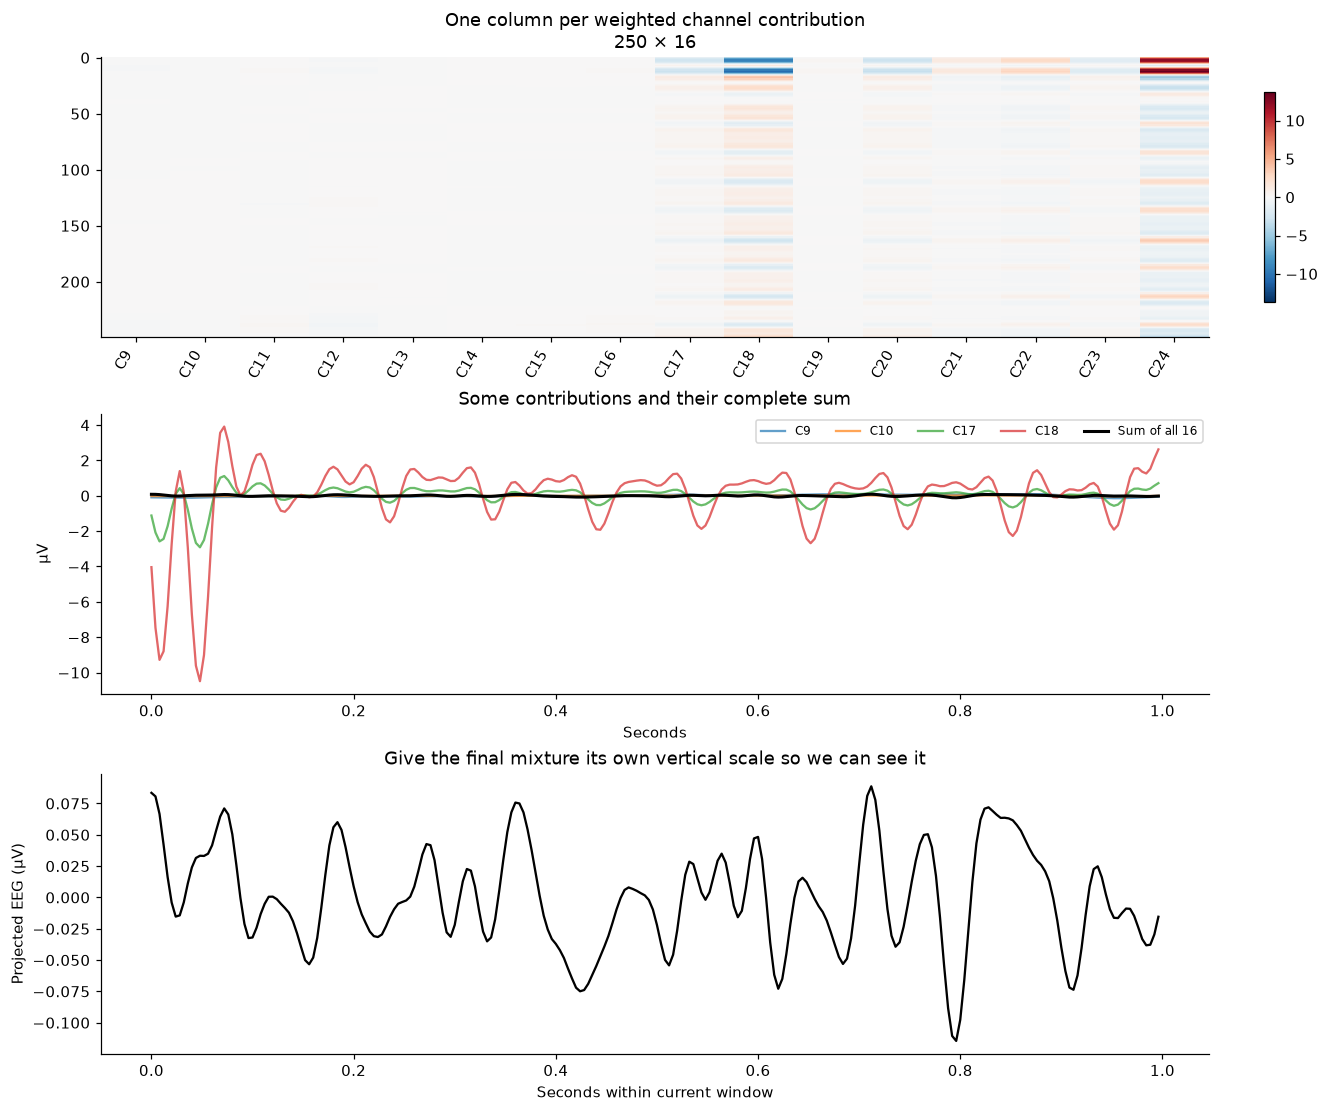

In [31]:
contributions=fit["X"].astype(float)*fit["hw_weights"].astype(float)[None,:]
projected_line=contributions.sum(axis=1)
display(pd.DataFrame({"Centered EEG at first moment":fit["X"][0],
                      "Weight":fit["hw_weights"],
                      "Multiply":contributions[0],
                      "Running total":np.cumsum(contributions[0])},index=CHANNEL_NAMES))
fig,axes=plt.subplots(3,1,figsize=(12,10),constrained_layout=True)
heatmap(axes[0],contributions,"One column per weighted channel contribution",columns=CHANNEL_NAMES)
for j in (0,1,8,9):axes[1].plot(t,contributions[:,j],label=CHANNEL_NAMES[j],alpha=.7)
axes[1].plot(t,projected_line,color="black",lw=2,label="Sum of all 16")
axes[1].set(title="Some contributions and their complete sum",xlabel="Seconds",ylabel="µV");axes[1].legend(ncol=5,fontsize=8)
axes[2].plot(t,projected_line,color="black")
axes[2].set(title="Give the final mixture its own vertical scale so we can see it",
            xlabel="Seconds within current window",ylabel="Projected EEG (µV)")
plt.show()

### Draw the associated reference line too

The final EEG mixture has a matching reference recipe. As before, compare it with sine/cosine, then use the reference undo table to obtain the reference multipliers.

Add the weighted sine and cosine values at each moment to obtain the reference line. Its numbers do not have EEG voltage units.

To compare shapes visually, divide each line by **its own size**: square its entries, add them, take the square root, divide. We have already used this operation. It removes the difference in overall size from the picture.

The lower panel below therefore shows patterns, not their original amplitudes. The ordinary correlation of these two displayed lines is a useful check, but it is not automatically identical to the finite-step firmware score.

Ordinary correlation of this pair: 0.45546546533451154
Firmware-style eight-step score: 0.4432784914970398


,Reference,Multiplier
0,Sine,0.014006
1,Cosine,0.021630


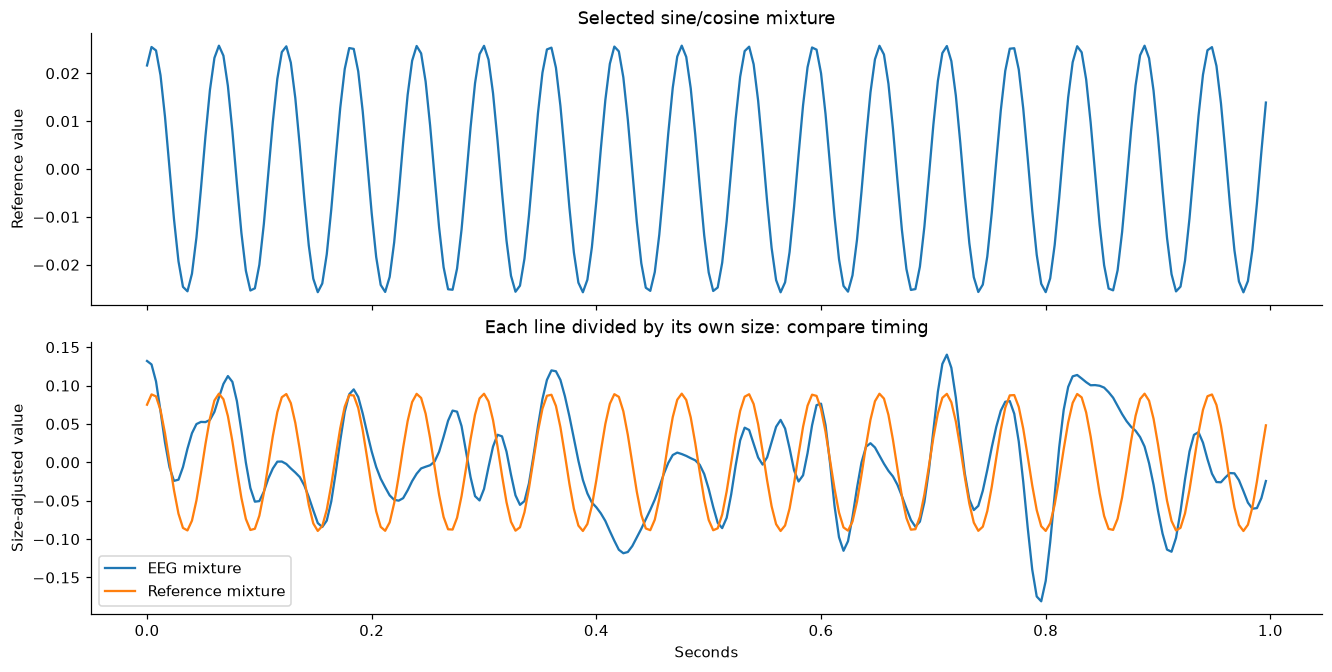

In [32]:
reference_weights_readable=fit["B_inv"].astype(float)@fit["Cxy"].astype(float).T@fit["hw_weights"].astype(float)
associated_reference=fit["Y"].astype(float)@reference_weights_readable
display(pd.DataFrame({"Reference":["Sine","Cosine"],"Multiplier":reference_weights_readable}))
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True,constrained_layout=True)
axes[0].plot(t,associated_reference);axes[0].set(title="Selected sine/cosine mixture",ylabel="Reference value")
for name,line in [("EEG mixture",projected_line),("Reference mixture",associated_reference)]:
    centered=line-line.mean();size=np.sqrt(sum(centered*centered))
    axes[1].plot(t,centered/size if size>0 else centered,label=name)
axes[1].set(title="Each line divided by its own size: compare timing",
            xlabel="Seconds",ylabel="Size-adjusted value");axes[1].legend();plt.show()
print("Ordinary correlation of this pair:",np.corrcoef(projected_line,associated_reference)[0,1])
print("Firmware-style eight-step score:",fit["hardware_score"])

## 27. What is a “dimension” here?

A channel gives one number at each moment. A fitted mixture also gives one number at each moment. We can treat this new measurement as a new column or **coordinate**. That column is one **dimension** of the transformed data.

Two different recipes can give two new columns. At one moment, take the first new value and the second new value and put a dot at that position on a graph. The horizontal position is the first value; the vertical position is the second. One dot represents one moment, not one electrode.

Here is another small example. Suppose:
- Channel A = sine + cosine.
- Channel B = sine − cosine.

Recipe [0.5, 0.5] gives sine.
Recipe [0.5, −0.5] gives cosine.

We have changed two original channel columns into two new coordinate columns. The plots show the same four moments before and after this change.

**A dimension is not automatically a brain region, an electrode, or a harmonic.** It is a new way to describe measurements using a recipe. The words “CCA dimension” mean that the recipe was chosen by CCA's matching rule.

,Channel A,Channel B,New coordinate 1: sine,New coordinate 2: cosine
Moment 1,1.0,-1.0,0.0,1.0
Moment 2,1.0,1.0,1.0,0.0
Moment 3,-1.0,1.0,0.0,-1.0
Moment 4,-1.0,-1.0,-1.0,0.0


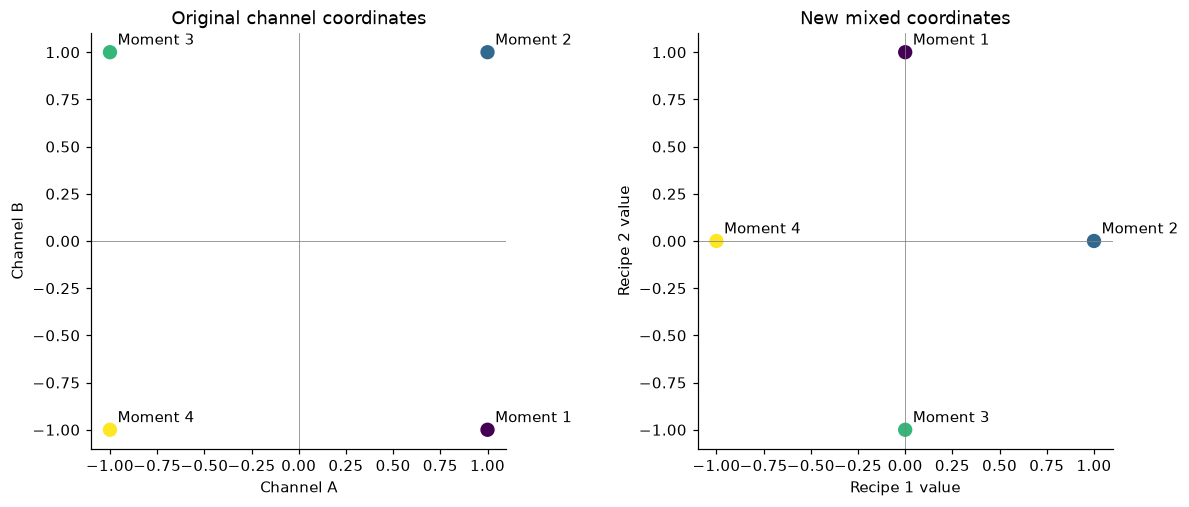

In [33]:
coordinate_channels=np.column_stack((toy_sine+toy_cosine,toy_sine-toy_cosine))
coordinate_recipes=np.array([[.5,.5],[.5,-.5]])
new_coordinates=coordinate_channels@coordinate_recipes
display(pd.DataFrame({"Channel A":coordinate_channels[:,0],"Channel B":coordinate_channels[:,1],
                      "New coordinate 1: sine":new_coordinates[:,0],"New coordinate 2: cosine":new_coordinates[:,1]},
                     index=["Moment 1","Moment 2","Moment 3","Moment 4"]))
fig,axes=plt.subplots(1,2,figsize=(11,4.5),constrained_layout=True)
for ax,values,title,labels in zip(axes,[coordinate_channels,new_coordinates],
                                ["Original channel coordinates","New mixed coordinates"],
                                [("Channel A","Channel B"),("Recipe 1 value","Recipe 2 value")]):
    ax.scatter(values[:,0],values[:,1],c=np.arange(4),s=70,cmap="viridis")
    for j in range(4):ax.annotate(f"Moment {j+1}",values[j],xytext=(5,5),textcoords="offset points")
    ax.axhline(0,color="gray",lw=.5);ax.axvline(0,color="gray",lw=.5)
    ax.set(title=title,xlabel=labels[0],ylabel=labels[1],aspect="equal")
plt.show()

## 28. Why CCA has a first and a second matched dimension

The first pair of recipes seeks the strongest match between an EEG mixture and a reference mixture.

For the second pair, we want a different matched pattern. Simply doubling the first mixture does not create new information. The full CCA calculation requires the next pair not to reuse the first pair's direction, using its size-and-overlap accounting rule. In ordinary unregularized CCA, the two EEG coordinate lines have zero net multiply-and-add comparison with each other; the two reference coordinate lines do too. Regularization slightly changes that comparison rule.

Our sine/cosine example makes this visible: sine compared with cosine gives zero, while each has a positive comparison with itself. They describe different timing patterns. A second dimension can therefore represent a different phase-related combination at the **same frequency**. It need not represent a second frequency.

The reference table has only two columns. There can be no more than **two independent matched CCA pairs** per target. Your EEG has 16 channels, but the reference side does not provide 16 different matched patterns.

Some software plots 16 entries for the 16-by-16 M table. Only up to two can have nonzero mathematical matching strength; the other 14 are zeros. Those extra zeros are not 14 additional fitted reference pairs, and they do not say the EEG contains no other activity.

The firmware estimates only the strongest direction. The full first/second dimension plots are an extra offline calculation. Before showing them, let us see what “account for size and overlap” means with our little example.

## 29. Make comparison columns equal in size and remove repeated information

In the two-channel example, Channel 1 has squared size 18 and Channel 2 has squared size 4. We should not favor Channel 1 merely because it is taller.

First divide Channel 1 by √18. Its squared-entry total becomes 1.

The second channel also shares a pattern with the first. The part of Channel 2 accounted for by Channel 1 uses this multiplier:
**“Channel 2 with Channel 1” ÷ “Channel 1 with itself” = 8 ÷ 18.**

This is the same reference-fitting division we already explained. Subtract **(8/18) × Channel 1** from Channel 2. Now the leftover has zero net comparison with Channel 1.

Divide that leftover by its own size. Its squared-entry total becomes 1 too.

We now have two replacement columns:
- Both have squared size 1.
- Their multiply-and-add comparison is 0.

This process of removing overlap and rescaling is called **whitening**. It does not mean deleting everything unusual or turning the signal white on a plot. It creates balanced comparison coordinates.

Apply the same idea to the two reference columns. They already have zero overlap, so in this example each just needs division by √2.

For real EEG, the calculation handles all 16 channels and uses the regularized tables A and B, so the balancing includes the small extra diagonal costs. The following example omits those additions to keep every number checkable.

,Original channel 1,Original channel 2,Remove (8/18) × channel 1 from channel 2,Balanced column 1,Balanced column 2
0,2.0,1.0,0.111111,0.471405,0.166667
1,-1.0,-1.0,-0.555556,-0.235702,-0.833333
2,2.0,1.0,0.111111,0.471405,0.166667
3,-3.0,-1.0,0.333333,-0.707107,0.500000


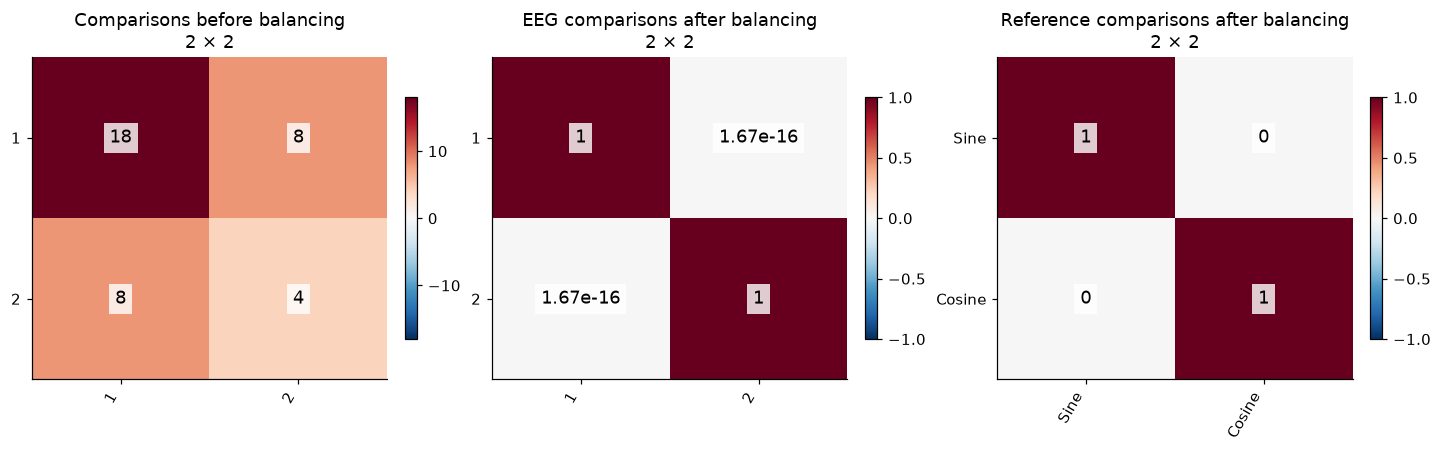

In [34]:
first_balanced=toy_x[:,0]/np.sqrt(sum(toy_x[:,0]**2))
shared_multiplier=(toy_x[:,1]@toy_x[:,0])/(toy_x[:,0]@toy_x[:,0])
second_leftover=toy_x[:,1]-shared_multiplier*toy_x[:,0]
second_balanced=second_leftover/np.sqrt(sum(second_leftover**2))
balanced_x=np.column_stack((first_balanced,second_balanced))
balanced_y=toy_y/np.sqrt(2)
display(pd.DataFrame({"Original channel 1":toy_x[:,0],"Original channel 2":toy_x[:,1],
                      "Remove (8/18) × channel 1 from channel 2":second_leftover,
                      "Balanced column 1":first_balanced,"Balanced column 2":second_balanced}))
fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
show_small(axes[0],toy_cxx,"Comparisons before balancing",["1","2"],["1","2"])
show_small(axes[1],balanced_x.T@balanced_x,"EEG comparisons after balancing",["1","2"],["1","2"])
show_small(axes[2],balanced_y.T@balanced_y,"Reference comparisons after balancing",["Sine","Cosine"],["Sine","Cosine"])
plt.show()

### Find matched recipes in those balanced coordinates

Compare the balanced EEG columns with the balanced reference columns. The new table is approximately:

| | Balanced sine | Balanced cosine |
|---|---:|---:|
| Balanced EEG column 1 | 0.333 | 0 |
| Balanced EEG column 2 | −0.943 | 0 |

The first column says which combination of the balanced EEG columns follows the sine. Its squared numbers add to **0.333² + (−0.943)² = 1**, allowing for rounding.

Use the recipe **[0.333, −0.943]** on the balanced EEG columns. It produces exactly the balanced sine line. The match has strength 1. The cosine column has only zeros, so this example has no second nonzero matched strength. Its original EEG columns contain sine and the unrelated wave, not cosine.

The full calculation finds the strongest such pair and then a second pair under the no-reuse rule. The computer method is called **singular value decomposition**, abbreviated SVD. Its role here is to find these matched recipes and their strengths from the balanced comparison table. You have now seen the inputs, goal, and one complete small numerical result; you do not need to memorize a software algorithm to interpret a dimension plot.

For your real data, the helper uses a stable numerical procedure to balance the tables and solve for both pairs in double precision. This is different from the board's eight-step shortcut. Both describe the regularized CCA matching problem, with differences from approximation and rounding.

First strength in this teaching example: 1.0
Second strength in this teaching example: 0


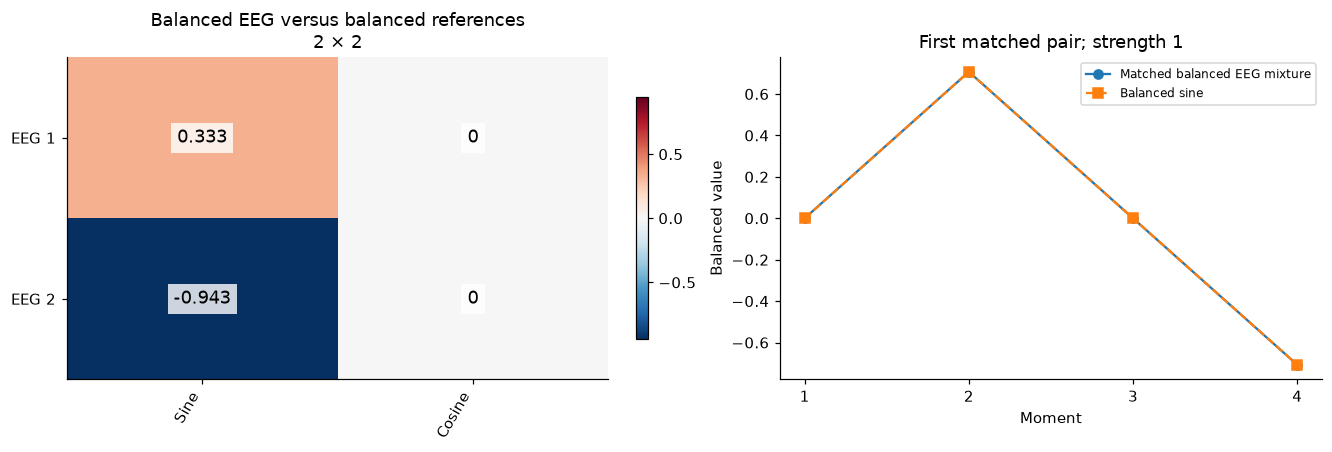

In [35]:
balanced_cross=balanced_x.T@balanced_y
balanced_recipe=balanced_cross[:,0]/np.linalg.norm(balanced_cross[:,0])
balanced_match=balanced_x@balanced_recipe
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
show_small(axes[0],balanced_cross,"Balanced EEG versus balanced references",["EEG 1","EEG 2"],["Sine","Cosine"])
axes[1].plot(range(1,5),balanced_match,"o-",label="Matched balanced EEG mixture")
axes[1].plot(range(1,5),balanced_y[:,0],"s--",label="Balanced sine")
axes[1].set(title="First matched pair; strength 1",xlabel="Moment",ylabel="Balanced value",xticks=range(1,5))
axes[1].legend(fontsize=8);plt.show()
print("First strength in this teaching example:",np.linalg.norm(balanced_cross[:,0]))
print("Second strength in this teaching example:",0)

## 30. Read the real CCA dimension plots

Each target gets its own fit. The first panel below shows two bars per target:
- **Dimension 1 strength**: strongest full mathematical match in this window.
- **Dimension 2 strength**: strongest remaining match under the no-reuse rule.

The bars are size-adjusted comparisons, not voltages, amounts of brain activity, or probability.

The second row plots one dot per actual time sample, using the two exact EEG mixtures as coordinates. For this picture, each recipe has squared weights adding to 1, so its mixed EEG line has µV units. The choice of recipe size sets the coordinate scale; it does not change which relative recipe it represents. The helper also provides another conventional CCA scaling, but we do not need that alternative to read this graph.

The colored dot tells you where the sample falls in the current second. This is a view of the same EEG measurements through new recipes, not a map of brain locations.

These are **offline exact diagnostic** dimensions. The board uses its own finite-step leading recipe for the live score, so the first diagnostic strength need not perfectly equal the board score.

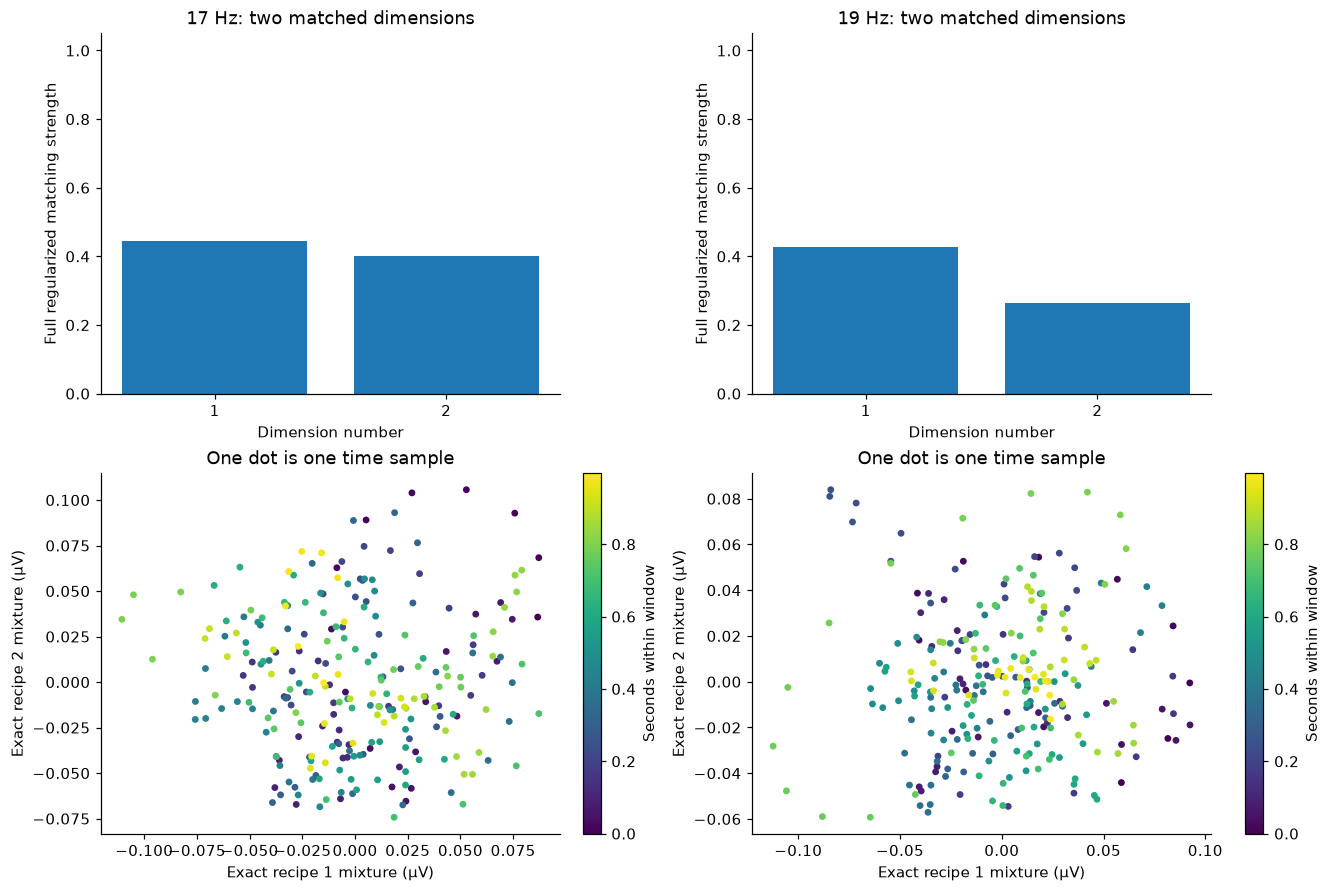

In [36]:
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for j,ff in enumerate(fits):
    axes[0,j].bar([1,2],ff["strengths"])
    axes[0,j].set(title=f"{ff['frequency']:g} Hz: two matched dimensions",
                  xlabel="Dimension number",ylabel="Full regularized matching strength",xticks=[1,2],ylim=(0,1.05))
    scatter=axes[1,j].scatter(ff["exact_U"][:,0],ff["exact_U"][:,1],c=t,cmap="viridis",s=12)
    axes[1,j].set(title="One dot is one time sample",
                  xlabel="Exact recipe 1 mixture (µV)",ylabel="Exact recipe 2 mixture (µV)")
    fig.colorbar(scatter,ax=axes[1,j],label="Seconds within window")
plt.show()

## 31. A spectrum asks a different question: what rhythms are in a line?

We have one projected EEG line, measured over time. Its **frequency spectrum** describes how much of its variation occurs at different repetition rates.

A repetition rate of 17 Hz means 17 cycles in a second; 19 Hz means 19 cycles. To understand the spectrum, start with a line we construct:
**2 × 17 Hz sine + 0.5 × 19 Hz cosine.**

We can look for the 17 Hz part by comparing this line with the 17 Hz sine/cosine references. The same multiply-and-add comparisons, divided by the references' squared sizes, recover multipliers **2 and 0**.

The 19 Hz comparisons recover **0 and 0.5**. There is no hidden new operation in this simple frequency measurement: we ask how much sine/cosine at each frequency is present.

To summarize the amount without caring whether it is sine or cosine, square both multipliers and add them. For a complete-cycle sine/cosine pair, divide by 2 to obtain its average squared contribution:
- At 17 Hz: (2² + 0²) ÷ 2 = **2**.
- At 19 Hz: (0² + 0.5²) ÷ 2 = **0.125**.

This is called **power** here: average squared signal size. It is not the correlation score. The 17 Hz contribution has 16 times as much power in this constructed line, because 2 ÷ 0.125 = 16.

A spectrum repeats this idea at many frequencies. The computer can calculate those comparisons efficiently with a method called a Fourier transform; the name describes the method, not a different question.

,Frequency (Hz),Sine multiplier,Cosine multiplier,Average squared contribution
0,17.0,2.0,0.0,2.000
1,19.0,0.0,0.5,0.125


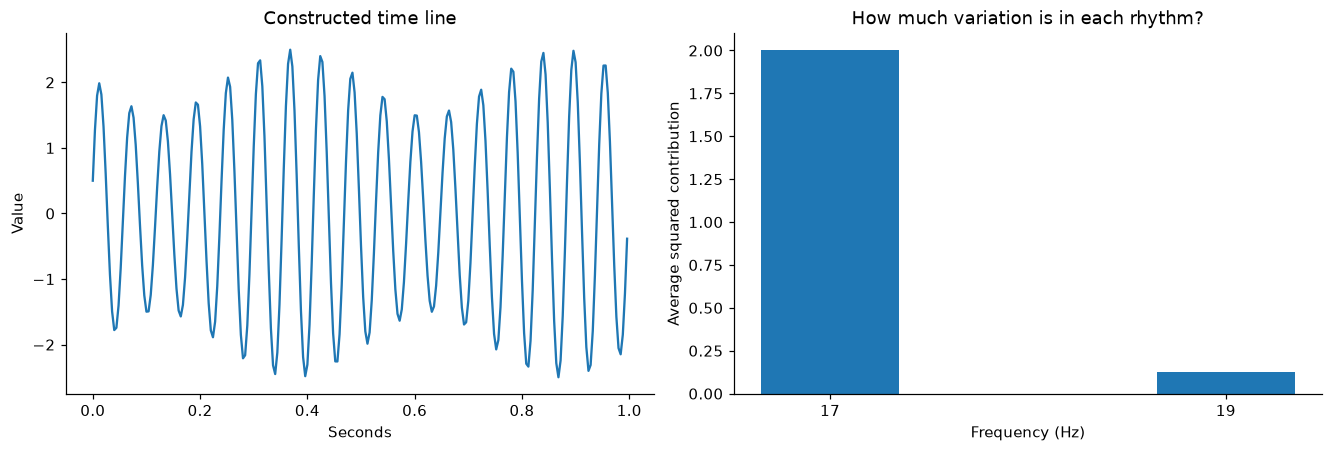

In [37]:
spectrum_demo=2*REFERENCES[17.][0][:,0]+.5*REFERENCES[19.][0][:,1]
spectrum_demo_rows=[]
for target in TARGETS:
    ref=REFERENCES[target][0].astype(float)
    coeff=np.linalg.solve(ref.T@ref,ref.T@spectrum_demo.astype(float))
    spectrum_demo_rows.append({"Frequency (Hz)":target,"Sine multiplier":coeff[0],
                              "Cosine multiplier":coeff[1],"Average squared contribution":sum(coeff*coeff)/2})
display(pd.DataFrame(spectrum_demo_rows).round(6))
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axes[0].plot(t,spectrum_demo)
axes[0].set(title="Constructed time line",xlabel="Seconds",ylabel="Value")
axes[1].bar([17,19],[r["Average squared contribution"] for r in spectrum_demo_rows],width=.7)
axes[1].set(title="How much variation is in each rhythm?",
            xlabel="Frequency (Hz)",ylabel="Average squared contribution",xticks=[17,19])
plt.show()

### Read the spectrum of the actual projected EEG

The plots below use the actual mixed EEG lines. First construct each line using its fitted weights; **then** calculate that line's spectrum.

The horizontal axis is waveform frequency, in Hz. The vertical axis is **power per Hz**, commonly called power spectral density or PSD. Because the waveform uses µV, its squared size uses µV²; power per Hz uses **µV²/Hz**. A high part of the curve says that this line has more variation near that repetition rate.

Our window contains 250 samples sampled 250 times per second. The unpadded spectrum has frequency points spaced 1 Hz apart. Plotting more points by adding zeros would make a smoother-looking curve, not add more recorded information.

For the plotted estimate, samples near the edges get less weight than central samples. This limits spreading caused by a window's abrupt edges. Multiplying samples by these time weights is called a **taper**. Our chosen taper is called DPSS, with settings NW=1 and one taper. You can read the spectrum without memorizing that name. It is an offline plotting choice: **the firmware does not taper its CCA input**.

A good correlation can occur for a small-amplitude line. Therefore a high CCA score does not necessarily imply a high PSD. Also, fitting a direction specifically to 17 Hz can emphasize a 17 Hz pattern in that same data, including noise. This is a descriptive view, not independent evidence of attention.

Multiplying an original channel's PSD by a CCA score would only rescale a graph. It would not produce the mixed waveform we have calculated.

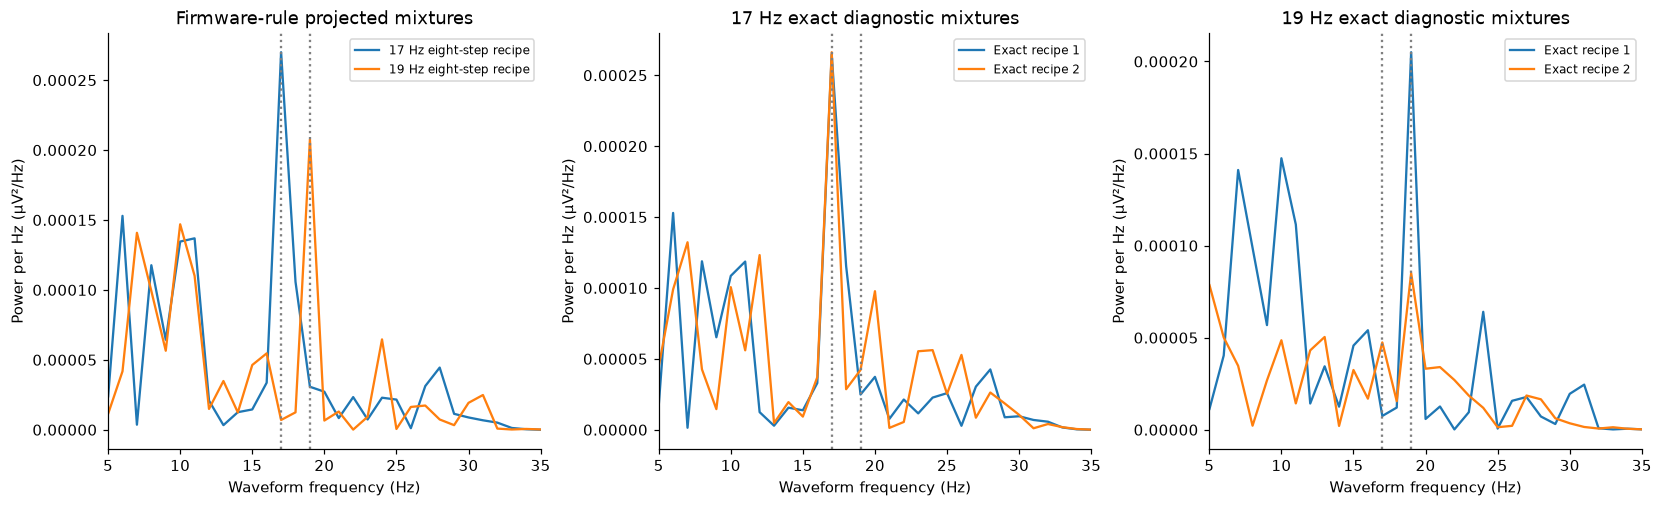

In [38]:
fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
for j in range(2):
    ff=fits[j]
    freq,p=psd(ff["hw_U"])
    axes[0].plot(freq,p,label=f"{ff['frequency']:g} Hz eight-step recipe")
    freq,p=psd(ff["exact_U"])
    for k in range(2):axes[j+1].plot(freq,p[:,k],label=f"Exact recipe {k+1}")
    axes[j+1].set_title(f"{ff['frequency']:g} Hz exact diagnostic mixtures")
axes[0].set_title("Firmware-rule projected mixtures")
for ax in axes:
    for target in TARGETS:ax.axvline(target,ls=":",color="gray")
    ax.set(xlim=(5,35),xlabel="Waveform frequency (Hz)",ylabel="Power per Hz (µV²/Hz)")
    ax.legend(fontsize=8)
plt.show()

## 32. Keep the two meanings of “CCA spectrum” separate

| Plot | What we put on the horizontal axis | What we measure |
|---|---|---|
| Spectrum of projected EEG | Repetition rate, in Hz | Power in the mixed EEG line near that frequency |
| CCA dimension spectrum | First dimension, second dimension | Matching strength of each fitted pair |

A third possible plot refits CCA using many candidate reference frequencies and shows a score for each. That is a **scan of CCA scores**. It is another question: “how well can I fit a reference at this candidate frequency?” It is not the waveform's power spectrum.

You have now seen both of the professor's requested interpretations. The spectrum notebook averages these kinds of results over the selected recordings, while this lesson shows the individual operations.

## 33. What changes 0.1 seconds later?

At 250 samples per second, 25 new samples take 0.1 seconds. The board keeps the latest 250 samples. The oldest 25 leave and the new 25 enter.

It repeats all of the following for the new window:
1. Calculate each channel's time average and subtract it.
2. Rebuild the EEG and EEG/reference comparison tables.
3. Calculate the small diagonal addition and the EEG undo table.
4. Build a round-trip table M for each target.
5. Start **again** from sixteen weights of 0.25.
6. Perform eight steps and compute two new scores.

The old final weights are not kept as the new starting weights. There is no first-second calibration whose weights are frozen afterward.

The timeline below shows the actual logged windows. A window can contain measurements taken before a trial marker. Trial onset labels the task; it does not erase the board's recent data.

The lower heat maps show one final weight list per update. Here the horizontal axis is time, whereas in the earlier eight-step figure it was the step number **within one window**. These are different axes.

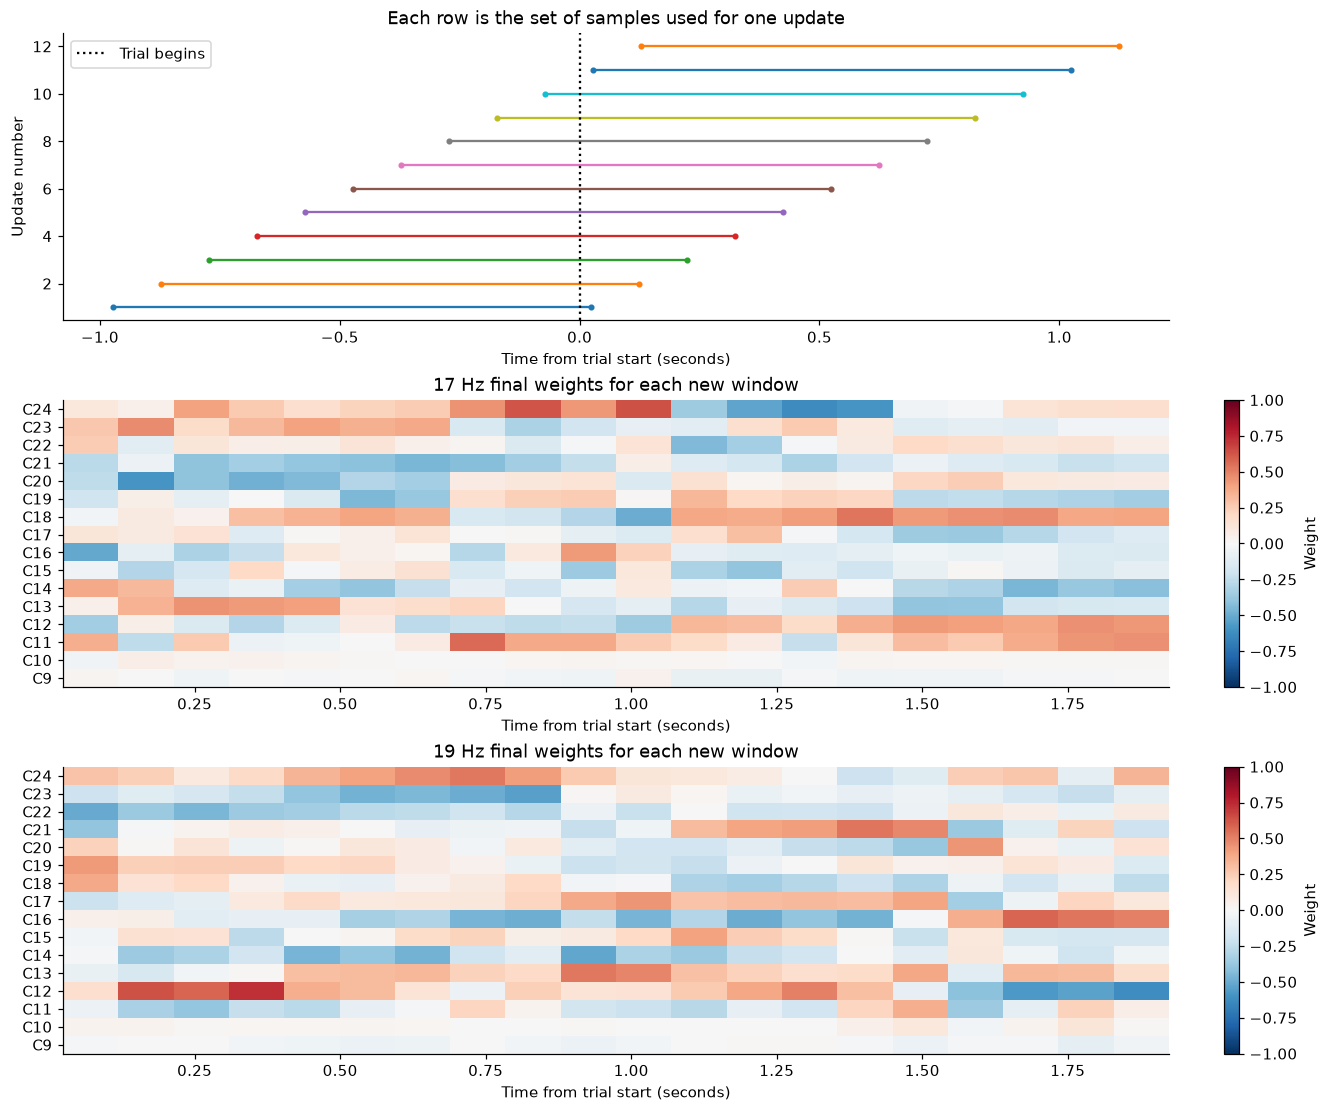

In [39]:
timeline=[];moving_weights=[]
for rr,xx in current_windows(rec,trial):
    qq=prepare_window(xx)
    current_fits=[fit_window(xx,target,qq) for target in TARGETS]
    timeline.append(rr.time)
    moving_weights.append(np.stack([ff["hw_weights"] for ff in current_fits],axis=-1))
timeline=np.asarray(timeline);moving_weights=np.asarray(moving_weights)
fig,axes=plt.subplots(3,1,figsize=(12,10),constrained_layout=True)
for i,stop in enumerate(timeline[:12]):axes[0].plot([stop-(WINDOW-1)/FS,stop],[i+1,i+1],"o-",ms=3)
axes[0].axvline(0,color="black",ls=":",label="Trial begins")
axes[0].set(title="Each row is the set of samples used for one update",
            xlabel="Time from trial start (seconds)",ylabel="Update number");axes[0].legend()
for j,target in enumerate(TARGETS):
    image=axes[j+1].imshow(moving_weights[:,:,j].T,aspect="auto",origin="lower",
                           extent=[timeline[0],timeline[-1],-.5,15.5],cmap="RdBu_r",vmin=-1,vmax=1)
    axes[j+1].set(title=f"{target:g} Hz final weights for each new window",
                  xlabel="Time from trial start (seconds)",yticks=range(16),yticklabels=CHANNEL_NAMES)
    fig.colorbar(image,ax=axes[j+1],label="Weight")
plt.show()

### Why not join all those projected lines and take one long spectrum?

Each update can use a different recipe. A sample described through one recipe is not automatically the same coordinate as a sample described through the next recipe.

Joining changing projections can add artificial jumps and mix different measurements into one line. Repeated windows also contain many of the same samples.

For a description matching live processing, calculate a projected spectrum **inside each window using its own recipe**, then average the resulting power values. That is what the spectrum notebook does.

A study that learns one recipe from training data and keeps it fixed on new data would answer a different question. It can be useful for independent evaluation, but it is not this firmware's live NF calculation.

## 34. The game needs one comparison between the two scores

CCA has produced two numbers: a score for the 17 Hz fit and a score for the 19 Hz fit. The firmware turns them into signed feedback.

Use simple example scores: **0.7 for 17 Hz** and **0.4 for 19 Hz**.

First subtract:
**0.7 − 0.4 = 0.3.**

Positive means the first score is larger. Negative means the second is larger. Zero means they are equal.

Current EMG32 then multiplies the difference by **2**:
**2 × 0.3 = 0.6.**

This multiplier is called the **gain**. It makes a given difference produce a larger control value. It does not change the CCA weights or scores.

Next keep the result between −1 and +1:
- If it is 1.4, use 1.
- If it is −1.4, use −1.
- If it is 0.6, keep 0.6.

This is called **clipping**. The feedback value for the opposite direction starts as the negative of this value. The board then smooths each direction as explained next.

,17 Hz score,19 Hz score,Subtract second from first,Multiply difference by 2,Keep between −1 and +1
0,0.70,0.40,0.30,0.6,0.6
1,0.40,0.70,-0.30,-0.6,-0.6
2,0.95,0.10,0.85,1.7,1.0
3,0.10,0.95,-0.85,-1.7,-1.0


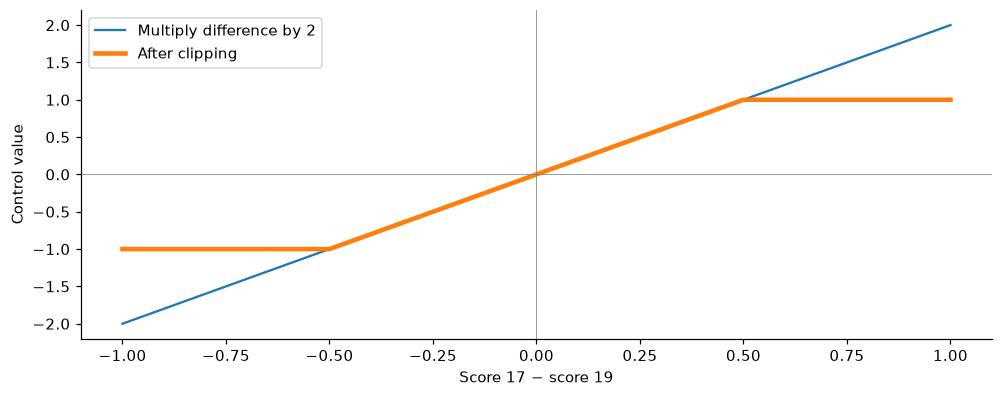

In [40]:
feedback_examples=pd.DataFrame({"17 Hz score":[.7,.4,.95,.1],
                                "19 Hz score":[.4,.7,.1,.95]})
feedback_examples["Subtract second from first"]=feedback_examples.iloc[:,0]-feedback_examples.iloc[:,1]
feedback_examples["Multiply difference by 2"]=2*feedback_examples["Subtract second from first"]
feedback_examples["Keep between −1 and +1"]=np.clip(feedback_examples["Multiply difference by 2"],-1,1)
display(feedback_examples)
fig,ax=plt.subplots(figsize=(9,3.5),constrained_layout=True)
differences=np.linspace(-1,1,201)
ax.plot(differences,2*differences,label="Multiply difference by 2")
ax.plot(differences,np.clip(2*differences,-1,1),label="After clipping",lw=3)
ax.axhline(0,color="gray",lw=.5);ax.axvline(0,color="gray",lw=.5)
ax.set(xlabel="Score 17 − score 19",ylabel="Control value");ax.legend();plt.show()

## 35. “Median” means the middle value after sorting

Take five recent clipped feedback values:
**[0.2, −0.1, 0.8, 0.3, 0.4]**.

Put them in order from smallest to largest:
**[−0.1, 0.2, 0.3, 0.4, 0.8]**.

The middle entry is **0.3**. That is the **median**. It is not the average. We did not add the five values and divide by five.

A single unusually high or low value often leaves the middle entry unchanged. That is why a median can reduce sudden spikes.

At each new update, put the latest value into the five-value list and discard the oldest value. Sort the five remaining values and take their middle. This is a **five-point running median**. “Point” here means one feedback update, not one EEG sample.

Five updates at the nominal 10-per-second rate are recent feedback history. Smoothing can make feedback change later than the unsmoothed difference, but it does not have one fixed delay for every pattern.

There is a startup detail in your code: after the board initializes the smoother, its first **five** successful pushes return the current value directly. Starting at push six, it returns the running median. Although five values exist at push five, the code still bypasses smoothing at that push. This is simply how its condition is written.

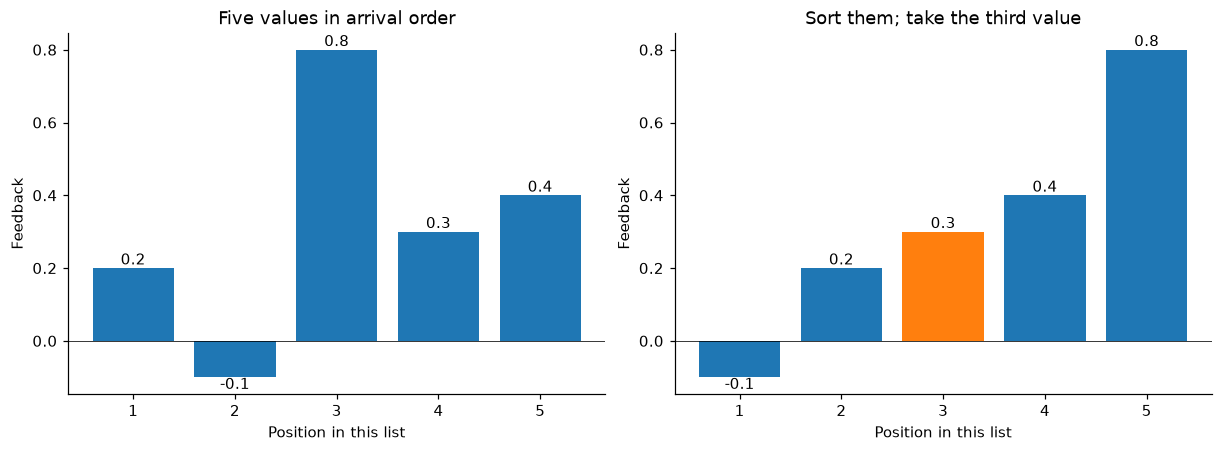

,Push number,Difference,After gain and clipping,Five latest values,Startup bypass or median
0,1,0.10,0.2,[0.2],0.2
1,2,0.20,0.4,"[0.2, 0.4]",0.4
2,3,0.05,0.1,"[0.2, 0.4, 0.1]",0.1
3,4,0.15,0.3,"[0.2, 0.4, 0.1, 0.3]",0.3
4,5,0.40,0.8,"[0.2, 0.4, 0.1, 0.3, 0.8]",0.8
5,6,-0.30,-0.6,"[0.4, 0.1, 0.3, 0.8, -0.6]",0.3
6,7,-0.20,-0.4,"[0.1, 0.3, 0.8, -0.6, -0.4]",0.1
7,8,0.10,0.2,"[0.3, 0.8, -0.6, -0.4, 0.2]",0.2


In [41]:
median_example=np.array([.2,-.1,.8,.3,.4])
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,values,title in zip(axes,[median_example,np.sort(median_example)],
                           ["Five values in arrival order","Sort them; take the third value"]):
    colors=["C0"]*5
    if title.startswith("Sort"):colors[2]="C1"
    ax.bar(range(1,6),values,color=colors)
    for j,value in enumerate(values):ax.text(j+1,value,f"{value:g}",ha="center",va="bottom" if value>=0 else "top")
    ax.axhline(0,color="black",lw=.5);ax.set(title=title,xlabel="Position in this list",ylabel="Feedback",xticks=range(1,6))
plt.show()
toy_diff=np.array([.1,.2,.05,.15,.4,-.3,-.2,.1])
toy_scores=np.column_stack((.5+toy_diff/2,.5-toy_diff/2))
toy_clipped=np.clip(2*toy_diff,-1,1)
toy_nf=nf_series(toy_scores,2,startup_known=True)
display(pd.DataFrame({"Push number":np.arange(1,9),"Difference":toy_diff,
                      "After gain and clipping":toy_clipped,
                      "Five latest values": [str(toy_clipped[max(0,i-4):i+1].tolist()) for i in range(8)],
                      "Startup bypass or median":toy_nf}))

## 36. Trial markers do not reset that five-value history

Two different things happen:
- **Weight search:** restarts from equal weights on every CCA update.
- **Median smoother:** keeps its recent feedback values across updates and trial markers.

A trial marker tells us what the participant/game is doing. The CCA compute function does not use that marker to clear the smoother, the EEG ring, or the continuous filter history.

The board initializes those histories at setup. If the EEG inverse calculation fails, it outputs zero scores and zero feedback and does not insert a new value into the median buffer. That is a separate failure path, not the normal median of a zero difference.

Your CSV files begin after the board is already running, so the initial five-value history is not fully recorded. We cannot invent that missing history. After five consecutive logged updates are available, we can normally reconstruct a running median. A missing update can make it unknown again until five consecutive values are available.

There is also a historical setting difference: the October 6 logs match **gain 1**, while the current firmware configuration says **gain 2**. We infer gain 1 from the recorded scores and feedback; we do not know the exact historical flashed binary.

Below, both formulas use the recorded board scores and continuous file history. The black line is recorded board feedback. The trial-start line does not cause a reset.

Largest eligible gain-1 reconstruction difference across the four files: 1.0000000000842668e-06
Small differences at this scale are consistent with CSV rounding.


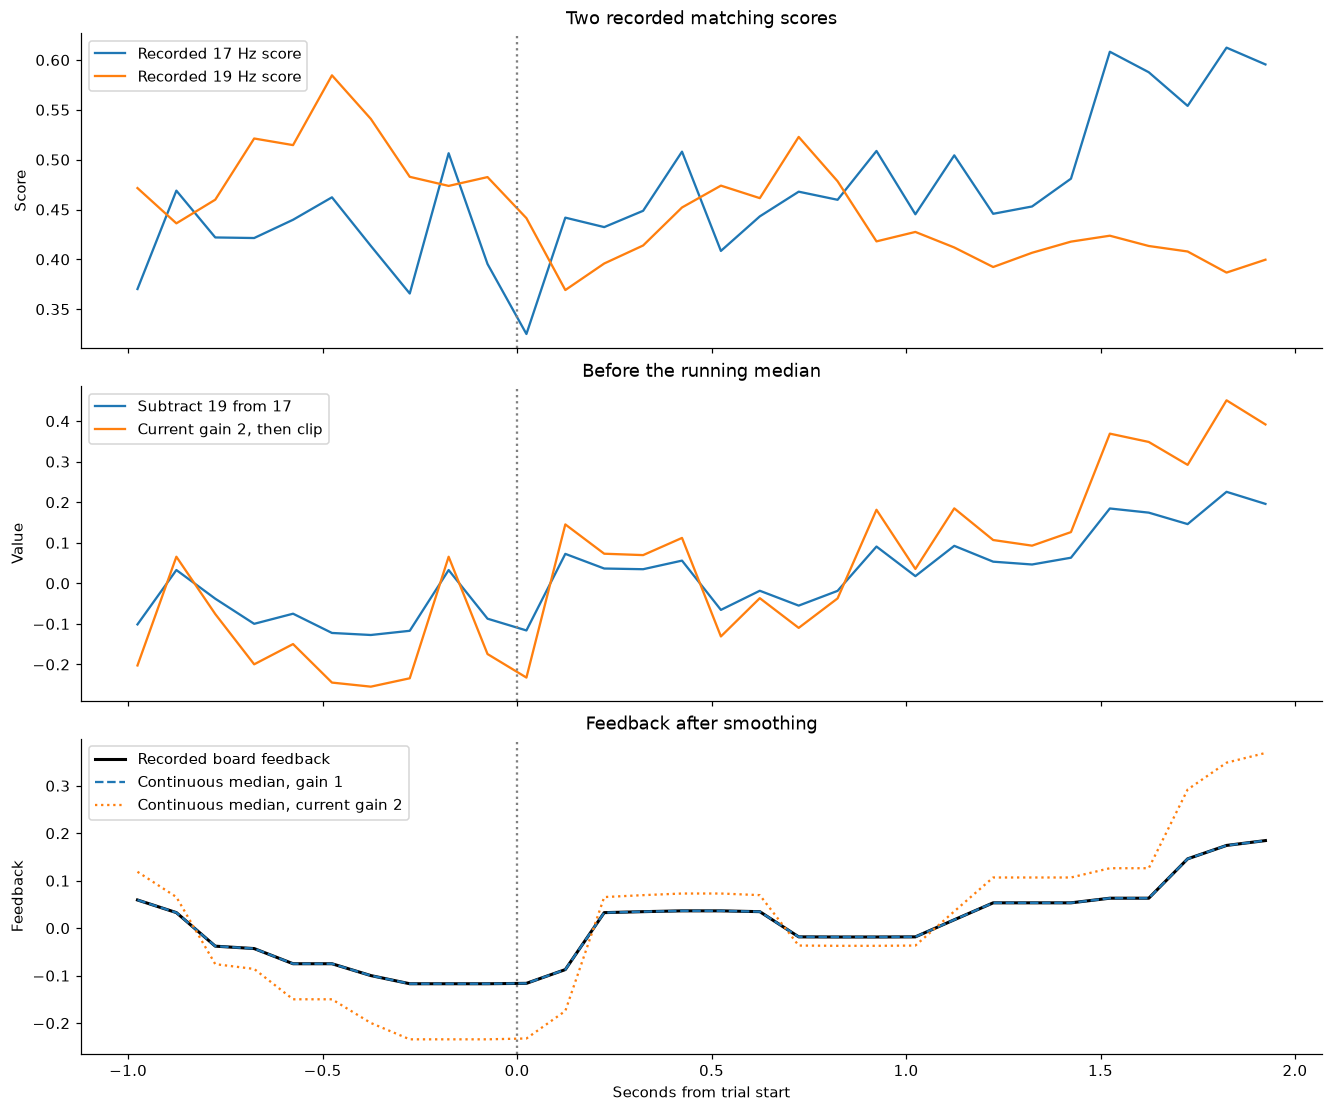

In [42]:
startseq=trial["start_seq"]
logged=rec["features"].loc[(rec["features"].seq>=startseq-250)&
                           (rec["features"].seq<startseq+500)].copy()
logged_time=(logged.seq-startseq)/FS
fig,axes=plt.subplots(3,1,figsize=(12,10),sharex=True,constrained_layout=True)
axes[0].plot(logged_time,logged.v3,label="Recorded 17 Hz score")
axes[0].plot(logged_time,logged.v4,label="Recorded 19 Hz score")
axes[0].set(title="Two recorded matching scores",ylabel="Score");axes[0].legend()
difference=logged.v3-logged.v4
axes[1].plot(logged_time,difference,label="Subtract 19 from 17")
axes[1].plot(logged_time,np.clip(2*difference,-1,1),label="Current gain 2, then clip")
axes[1].set(title="Before the running median",ylabel="Value");axes[1].legend()
axes[2].plot(logged_time,logged.recorded_nf,color="black",lw=2,label="Recorded board feedback")
axes[2].plot(logged_time,logged.nf_gain1,ls="--",label="Continuous median, gain 1")
axes[2].plot(logged_time,logged.nf_current_gain,ls=":",label="Continuous median, current gain 2")
axes[2].set(title="Feedback after smoothing",xlabel="Seconds from trial start",ylabel="Feedback")
axes[2].legend()
for ax in axes:ax.axvline(0,color="gray",ls=":")
plt.show()
assert audit.gain1_max.max()<2e-6
print("Largest eligible gain-1 reconstruction difference across the four files:",audit.gain1_max.max())
print("Small differences at this scale are consistent with CSV rounding.")

## 37. Follow one update from beginning to end

Read this as a sequence of ordinary operations:

1. **Take the newest second of filtered measurements.** There are 250 moments, each with 16 selected channel values.
2. **Remove each channel's time average.** This gives X.
3. **Compare columns by multiplying corresponding moments and adding.** Store EEG/EEG totals in Cxx and EEG/reference totals in Cxy.
4. **Add a small number to the EEG comparison table's diagonal.** This makes undoing that table more stable. The modified table is A.
5. **Calculate A's undo table.** The reference undo tables are already stored.
6. **Combine the comparison/undo tables into M.** This table performs the EEG → reference → EEG recipe round trip.
7. **Start with equal weights, repeat eight steps, keeping the weight-list size at 1.** Do this separately for 17 and 19 Hz.
8. **Estimate a stretching factor from the final list and take a square root.** Now we have one score per target.
9. **Subtract the scores, apply gain, clip, take the running median.** The board sends the resulting feedback values.

For pictures, this notebook additionally mixes the original EEG with the recovered weights, measures that line's spectrum, and shows the full offline CCA dimensions. Those extra plots are not extra inputs to the live feedback formula.

The TCP bridge copies the board feedback and update counter into the binary file nf.txt. It limits writes to at most 10 per second using the PC clock. The logged board updates do not prove that the game read every one of them.

This sequence describes the checked-out EMG32 source. The actual firmware uses finite-precision numbers. Our model follows its arithmetic order, but CSV rounding, numerical sensitivity, and an unknown historical build can produce differences. The spectrum notebook reports reconstruction errors against logged scores rather than claiming exact replay.

A useful match means the current data can be mixed to follow the reference. Because the recipe is fitted on that same window, the result can include noise or non-neural signals. It does not by itself prove attention or identify a brain source.

**Why is this called hardware-friendly CCA?** The board stores the reference waves and their undo tables ahead of time, shares one EEG undo table across the two target fits, and runs a fixed eight-step search instead of the full dimension calculation. Those choices reduce repeated work. The matching idea remains CCA; there is no separate first-second training stage.

## Reference sheet: names for operations you have now seen

| Name in the code or explanation | Meaning |
|---|---|
| Product | Result of multiplying two numbers |
| Product sum | Multiply corresponding entries, then add |
| Square | Multiply a number by itself |
| Square root | Positive number that squares to the given value |
| Correlation | For centered lines, product sum divided by their sizes multiplied together |
| Weight | Multiplier used in a channel recipe |
| Vector | Ordered list of numbers |
| Matrix | Rectangular table of numbers |
| Transpose | Exchange the table's rows and columns |
| Inverse | A table that undoes another table's transformation |
| Identity | Table with diagonal ones and other entries zero; leaves input unchanged |
| Regularization | Here, small positive diagonal additions that stabilize weight calculation |
| Normalize | Divide a whole list by its size |
| Power iteration | Repeat a table multiplication and normalize the weights |
| Eigenvector | Relative recipe that is unchanged by a table's multiplication |
| Eigenvalue | Stretching factor for such a recipe |
| Projection | New line made by multiplying channels by weights and adding |
| Dimension | One coordinate/column of a new representation |
| Whitening | Rescale comparison columns and account for their shared variation |
| SVD | Full numerical method used offline to find matched pairs from balanced comparisons |
| Spectrum | Description of variation at different waveform frequencies |
| PSD | Power per unit frequency |
| Gain | Multiplier applied to the score difference |
| Clip | Keep a value within chosen upper/lower limits |
| Median | Middle value after sorting |

You do not need to memorize this table. Return to the corresponding worked example whenever a name becomes unclear.

Original analysis.ipynb, cca.py, the spectrum notebook and the EMG32 firmware have not been changed by this teaching revision.